In [5]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

# Load the geocoded dataset
df_raw = pd.read_csv("../data/raw/housing_with_coords.csv", low_memory=False)

# Create a working copy for preprocessing
df = df_raw.copy()

# Display the initial dataset information
print("Initial shape:", df.shape)
print("Total rows:", len(df))
print("Total columns:", len(df.columns))

# Preview the dataset
display(df.head())

# Check column names and data types
df.info()



Initial shape: (10704, 69)
Total rows: 10704
Total columns: 69


,PROP_ID,PHOTO_URL,MEDIUM_PHOTO_URL,PREFERENCE,DESCRIPTION,PROPERTY_TYPE,CITY,LOCALITY,TRANSACT_TYPE,OWNTYPE,...,xid,metadata,location,BUILTUP_SQFT,SUPER_SQFT,COMMON_FURNISHING_ATTRIBUTES,QUALITY_SCORE,FURNISHING_ATTRIBUTES,latitude,longitude
0,O71585872,https://mediacdn.99acres.com/media1/22409/13/4...,https://mediacdn.99acres.com/media1/22409/13/4...,S,4 bhk flat for resale in alpha corp gurgaon one,Residential Apartment,Gurgaon,Sector 84 Gurgaon,1.0,1,...,"{'PROJECTID': 5096, 'PROJ_NAME': 'Alpha Corp G...","{'PROP_PHOTO_COUNT': '4', 'PROP_VIDEO_COUNT': ...","{'CITY': '8', 'CITY_NAME': 'Gurgaon', 'BUILDIN...",NaN,NaN,NaN,NaN,NaN,28.403547,76.967789
1,T71585466,https://mediacdn.99acres.com/media1/22425/6/44...,https://mediacdn.99acres.com/media1/22425/6/44...,S,"Explore dlf ultima, an upscale ready-To-Move h...",Residential Apartment,Gurgaon,Sector 81 Gurgaon,1.0,1,...,"{'PROJECTID': 7182, 'PROJ_NAME': 'DLF The Ulti...","{'PROP_PHOTO_COUNT': '4', 'PROP_VIDEO_COUNT': ...","{'CITY': '8', 'CITY_NAME': 'Gurgaon', 'BUILDIN...",NaN,NaN,NaN,NaN,NaN,28.387365,76.947583
2,D71549524,https://mediacdn.99acres.com/media1/22386/13/4...,https://mediacdn.99acres.com/media1/22386/13/4...,R,A 3 bhk flat for rent in sector 66 gurgaon clo...,Residential Apartment,Gurgaon,Sector 66 Gurgaon,NaN,0,...,"{'PROJECTID': 19, 'PROJ_NAME': 'Emaar MGF The ...","{'PROP_PHOTO_COUNT': '1', 'PROP_VIDEO_COUNT': ...","{'CITY': '8', 'CITY_NAME': 'Gurgaon', 'BUILDIN...",1920.00,NaN,NaN,NaN,NaN,28.397429,77.053882
3,I71493958,https://mediacdn.99acres.com/media1/22353/14/4...,https://mediacdn.99acres.com/media1/22353/14/4...,S,Looking for a 3 bhk property for purchase in g...,Residential Apartment,Gurgaon,Sector 112 Gurgaon,1.0,1,...,"{'PROJECTID': 4342, 'PROJ_NAME': 'Experion Win...","{'PROP_PHOTO_COUNT': '1', 'PROP_VIDEO_COUNT': ...","{'CITY': '8', 'CITY_NAME': 'Gurgaon', 'BUILDIN...",2225.56,NaN,NaN,NaN,NaN,28.520340,77.018861
4,H71479412,https://mediacdn.99acres.com/media1/22352/4/44...,https://mediacdn.99acres.com/media1/22352/4/44...,R,This 4 bhk flat in sector 104 gurgaon is avail...,Residential Apartment,Gurgaon,Sector 104 Gurgaon,NaN,0,...,"{'PROJECTID': 25860, 'PROJ_NAME': 'ATS Triumph...","{'PROP_PHOTO_COUNT': '14', 'PROP_VIDEO_COUNT':...","{'CITY': '8', 'CITY_NAME': 'Gurgaon', 'BUILDIN...",NaN,NaN,NaN,NaN,NaN,28.479532,76.993720


<class 'pandas.DataFrame'>
RangeIndex: 10704 entries, 0 to 10703
Data columns (total 69 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   PROP_ID                       10704 non-null  str    
 1   PHOTO_URL                     8864 non-null   str    
 2   MEDIUM_PHOTO_URL              8864 non-null   str    
 3   PREFERENCE                    10704 non-null  str    
 4   DESCRIPTION                   10704 non-null  str    
 5   PROPERTY_TYPE                 10704 non-null  str    
 6   CITY                          10704 non-null  str    
 7   LOCALITY                      10704 non-null  str    
 8   TRANSACT_TYPE                 10152 non-null  float64
 9   OWNTYPE                       10704 non-null  int64  
 10  BEDROOM_NUM                   10511 non-null  float64
 11  BATHROOM_NUM                  10704 non-null  int64  
 12  BALCONY_NUM                   10501 non-null  float64
 13  PRICE_PER_UN

In [6]:

# Create a log to track row counts during preprocessing
preprocessing_log = []

# Record the initial dataset
preprocessing_log.append({
    "Step": "Raw",
    "Rows before": len(df),
    "Rows after": len(df),
    "Rows removed": 0
})

# Display the log
log_df = pd.DataFrame(preprocessing_log)
display(log_df)



,Step,Rows before,Rows after,Rows removed
0,Raw,10704,10704,0


In [7]:
rows_before = len(df)

df = df.drop_duplicates()

rows_after = len(df)

preprocessing_log.append({
    "Step": "Remove duplicate records",
    "Rows before": rows_before,
    "Rows after": rows_after,
    "Rows removed": rows_before - rows_after
})

display(pd.DataFrame(preprocessing_log))

,Step,Rows before,Rows after,Rows removed
0,Raw,10704,10704,0
1,Remove duplicate records,10704,10704,0


In [8]:
# Save the preprocessing log
Path("../reports").mkdir(parents=True, exist_ok=True)

pd.DataFrame(preprocessing_log).to_csv(
    "../reports/preprocessing_log.csv",
    index=False
)

print("Preprocessing log saved successfully!")

Preprocessing log saved successfully!


In [9]:

# Standardize column names:
# lowercase, remove surrounding whitespace, replace spaces and hyphens with underscores

df.columns = (
    df.columns.str.strip()
    .str.lower()
    .str.replace(" ", "_", regex=False)
    .str.replace("-", "_", regex=False)
)

print("Column names standardized.")
print("Total columns:", len(df.columns))
print("\nColumn names:")
print(df.columns.tolist())



Column names standardized.
Total columns: 69

Column names:
['prop_id', 'photo_url', 'medium_photo_url', 'preference', 'description', 'property_type', 'city', 'locality', 'transact_type', 'owntype', 'bedroom_num', 'bathroom_num', 'balcony_num', 'price_per_unit_area', 'furnish', 'facing', 'age', 'floor_num', 'total_floor', 'features', 'register_date', 'prop_name', 'min_price', 'max_price', 'price_sqft', 'listing', 'building_id', 'carpet_sqft', 'superbuiltup_sqft', 'brokerage', 'map_details', 'fsl_data', 'min_area_sqft', 'max_area_sqft', 'formatted', 'amenities', 'top_usps', 'pd_url', 'expiry_date', 'group_name', 'area', 'price', 'prop_heading', 'prop_details_url', 'class_heading', 'class_label', 'secondary_tags', 'property_images', 'thumbnail_images', 'total_landmark_count', 'formatted_landmark_details', 'contact_name', 'contact_company_name', 'dealer_photo_url', 'society_name', 'building_name', 'city_id', 'locality_wo_city', 'profile', 'xid', 'metadata', 'location', 'builtup_sqft', 'su

In [11]:

# Remove leading and trailing whitespace from text columns

for col in df.select_dtypes(include="object").columns:
    df[col] = df[col].apply(
        lambda value: value.strip() if isinstance(value, str) else value
    )

print("Whitespace cleaning completed.")



C:\Users\hp\AppData\Local\Temp\ipykernel_20212\253116351.py:3: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  for col in df.select_dtypes(include="object").columns:


Whitespace cleaning completed.


In [12]:

# Calculate missing-value percentages for every column

missing_percent = (
    (df.isna().mean() * 100)
    .round(2)
    .sort_values(ascending=False)
)

print("Columns ranked by missing-value percentage:")
display(missing_percent.to_frame(name="Missing_Percentage"))

# Show columns with more than 40% missing values
high_missing = missing_percent[missing_percent > 40]

print("\nColumns with more than 40% missing values:")
display(high_missing.to_frame(name="Missing_Percentage"))



Columns ranked by missing-value percentage:


,Missing_Percentage
common_furnishing_attributes,100.00
quality_score,99.98
furnishing_attributes,99.98
super_sqft,91.83
builtup_sqft,74.47
...,...
locality_wo_city,0.00
city_id,0.00
dealer_photo_url,0.00
profile,0.00



Columns with more than 40% missing values:


,Missing_Percentage
common_furnishing_attributes,100.00
quality_score,99.98
furnishing_attributes,99.98
super_sqft,91.83
builtup_sqft,74.47


In [13]:
# Find columns with one or fewer distinct non-missing values

constant_columns = [
    col for col in df.columns
    if df[col].nunique(dropna=True) <= 1
]

print("Constant or entirely missing columns:")
print(constant_columns)

Constant or entirely missing columns:
['city', 'city_id', 'common_furnishing_attributes', 'quality_score']


In [14]:
# Drop reviewed constant or entirely missing columns.
# Keep latitude and longitude.

columns_to_drop = [
    col for col in constant_columns
    if col not in ["latitude", "longitude", "price"]
]

df = df.drop(columns=columns_to_drop, errors="ignore")

print("Columns dropped:", columns_to_drop)
print("Dataset shape after dropping constant columns:", df.shape)

Columns dropped: ['city', 'city_id', 'common_furnishing_attributes', 'quality_score']
Dataset shape after dropping constant columns: (10704, 65)


In [15]:
df = df.drop(columns=["society", "availability"], errors="ignore")

In [16]:
# Record the row count after standardization and constant-column removal

preprocessing_log.append({
    "Step": "Standardize columns and remove constant columns",
    "Rows before": len(df_raw),
    "Rows after": len(df),
    "Rows removed": len(df_raw) - len(df)
})

display(pd.DataFrame(preprocessing_log))

,Step,Rows before,Rows after,Rows removed
0,Raw,10704,10704,0
1,Remove duplicate records,10704,10704,0
2,Standardize columns and remove constant columns,10704,10704,0


In [17]:

# Inspect column names, data types, and non-null counts
df.info()

# Examine important columns available in the dataset
important_columns = [
    "price", "transact_type", "bedroom_num",
    "area", "carpet_sqft", "builtup_sqft",
    "superbuiltup_sqft", "price_per_unit_area", "age"
]

for col in important_columns:
    if col in df.columns:
        print(f"\n--- {col} ---")
        print("Data type:", df[col].dtype)
        print("Missing values:", df[col].isna().sum())
        print("Sample values:")
        print(df[col].dropna().head(10).tolist())



<class 'pandas.DataFrame'>
RangeIndex: 10704 entries, 0 to 10703
Data columns (total 65 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   prop_id                     10704 non-null  str    
 1   photo_url                   8864 non-null   str    
 2   medium_photo_url            8864 non-null   str    
 3   preference                  10704 non-null  str    
 4   description                 10704 non-null  str    
 5   property_type               10704 non-null  str    
 6   locality                    10704 non-null  str    
 7   transact_type               10152 non-null  float64
 8   owntype                     10704 non-null  int64  
 9   bedroom_num                 10511 non-null  float64
 10  bathroom_num                10704 non-null  int64  
 11  balcony_num                 10501 non-null  float64
 12  price_per_unit_area         10704 non-null  float64
 13  furnish                     10704 non-null

In [18]:
if "bedroom_num" in df.columns:
    print(df["bedroom_num"].value_counts(dropna=False).head(20))

bedroom_num
3.0     4975
4.0     3154
2.0     1695
5.0      362
NaN      193
1.0       92
6.0       62
9.0       47
10.0      33
7.0       28
8.0       18
12.0      18
11.0       6
16.0       4
22.0       4
18.0       3
21.0       3
19.0       2
20.0       2
14.0       2
Name: count, dtype: int64


In [19]:
area_columns = [
    "area", "carpet_sqft", "builtup_sqft",
    "superbuiltup_sqft", "super_sqft"
]

for col in area_columns:
    if col in df.columns:
        print(f"\n{col}:")
        print(df[col].dropna().head(15).tolist())


area:
['3434 sq.ft.', '2870 sq.ft.', '1950 sq.ft.', '2802 sq.ft.', '2290 sq.ft.', '2290 sq.ft.', '3150 sq.ft.', '1400 sq.ft.', '1629 sq.ft.', '2727 sq.ft.', '2340 sq.ft.', '4850 sq.ft.', '1400 sq.ft.', '1950 sq.ft.', '1950 sq.ft.']

carpet_sqft:
[3000.0, 1700.0, 1450.0, 3080.0, 1450.0, 1480.0, 1212.0, 950.0, 1150.0, 2200.0, 2200.0, 2010.0, 1296.93, 1289.0, 1020.0]

builtup_sqft:
[1920.0, 2225.56, 1920.0, 1920.0, 1700.0, 2420.0, 2210.0, 2678.0, 2680.0, 2500.0, 4980.0, 1939.03, 1500.0, 2525.0, 1750.0]

superbuiltup_sqft:
[3434.0, 2870.0, 1950.0, 2802.0, 2290.0, 2290.0, 3150.0, 1400.0, 2727.000000000273, 4850.0, 1400.0, 1950.0, 1950.0, 3880.0, 2165.0]

super_sqft:
[1629.0000000001628, 2340.0000000002337, 1935.0000000001933, 1535.0, 5000.0, 1579.0, 4968.0, 2088.0000000002087, 1080.000000000108, 512.0, 242.0, 3240.000000000324, 1935.0000000001933, 784080.000000011, 1125.0000000001123]


In [20]:
import re

def convert_area_sqft(value):
    if pd.isna(value):
        return np.nan

    text = str(value).strip().lower()
    text = text.replace(",", "")

    # Extract numeric values
    numbers = re.findall(r"\d+(?:\.\d+)?", text)

    if not numbers:
        return np.nan

    # Convert ranges such as 1200-1500 to their average
    if len(numbers) >= 2 and re.search(r"\d\s*-\s*\d", text):
        unit_text = text

        # Only accept ranges explicitly expressed in square feet
        # or values with no unit, provided the source field is known to be sqft.
        if any(unit in unit_text for unit in ["sq. meter", "sq meter", "sqm", "sq. yard", "sq yard", "acre", "perch"]):
            return np.nan

        return (float(numbers[0]) + float(numbers[1])) / 2

    # Reject measurements expressed in unsupported units
    if any(unit in text for unit in [
        "sq. meter", "sq meter", "sqm",
        "sq. yard", "sq yard", "acre", "perch"
    ]):
        return np.nan

    return float(numbers[0])

In [21]:
if "carpet_sqft" in df.columns:
    df["carpet_sqft"] = df["carpet_sqft"].apply(convert_area_sqft)

    print(
        "Missing or unparseable carpet area values:",
        df["carpet_sqft"].isna().sum()
    )

Missing or unparseable carpet area values: 4165


In [22]:
# Compare original and cleaned carpet area values

print("Original carpet_sqft values:")
print(df_raw["CARPET_SQFT"].head(20).tolist())

print("\nMissing values before conversion:")
print(df_raw["CARPET_SQFT"].isna().sum())

print("\nMissing values after conversion:")
print(df["carpet_sqft"].isna().sum())

Original carpet_sqft values:
[3000.0, 1700.0, 1450.0, nan, nan, nan, nan, nan, nan, nan, nan, 3080.0, nan, 1450.0, 1480.0, nan, nan, nan, nan, nan]

Missing values before conversion:
4165

Missing values after conversion:
4165


In [23]:
# Display examples of original carpet-area values that are not numeric

original_area = df_raw["CARPET_SQFT"]

print("Original data type:", original_area.dtype)

print("\nMost common original values:")
print(original_area.value_counts(dropna=False).head(25))

Original data type: float64

Most common original values:
CARPET_SQFT
NaN       4165
2000.0     174
1500.0     167
1800.0     149
1600.0     148
2200.0     123
1200.0     121
1400.0     114
1700.0      99
1550.0      98
1000.0      92
2500.0      91
2700.0      81
2100.0      79
1250.0      76
1900.0      74
1100.0      73
1450.0      71
2400.0      67
1300.0      66
2700.0      65
1650.0      62
3000.0      57
1750.0      56
1350.0      54
Name: count, dtype: int64


In [24]:
original_missing = df_raw["CARPET_SQFT"].isna().sum()
cleaned_missing = df["carpet_sqft"].isna().sum()

print("Originally missing:", original_missing)
print("Missing after conversion:", cleaned_missing)
print("Additional missing values:", cleaned_missing - original_missing)

Originally missing: 4165
Missing after conversion: 4165
Additional missing values: 0


In [25]:
if "transact_type" in df.columns:
    print(df["transact_type"].value_counts(dropna=False))

transact_type
1.0    10140
NaN      552
2.0       12
Name: count, dtype: int64


In [26]:
print("Sample raw prices:")
print(df["price"].dropna().sample(
    min(20, df["price"].notna().sum()),
    random_state=42
).tolist())

Sample raw prices:
['1.9 Cr', '6 Cr', '2.55 Cr', '3.75 Cr', '3.85 Cr', '53 L', '1.13 Cr', '7 Cr', '1.62 Cr', '1.5 Cr', '1.78 Cr', '60,000', '1.35 Cr', '9.89 Cr', '1.45 Cr', '2.43 Cr', '21.75 Cr', '1.68 Cr', '2.32 Cr', '85,000']


In [27]:
def convert_price_to_lakhs(value):
    if pd.isna(value):
        return np.nan

    text = str(value).strip().lower()
    text = text.replace(",", "").replace("₹", "").strip()

    try:
        if text.endswith("crore") or text.endswith("crores"):
            number = re.sub(r"\s*crores?$", "", text).strip()
            return float(number) * 100

        if text.endswith("cr"):
            return float(text[:-2].strip()) * 100

        if text.endswith("lakh") or text.endswith("lakhs"):
            number = re.sub(r"\s*lakhs?$", "", text).strip()
            return float(number)

        if text.endswith("lac") or text.endswith("lacs"):
            number = re.sub(r"\s*lacs?$", "", text).strip()
            return float(number)

        if text.endswith("l"):
            return float(text[:-1].strip())

        # Unlabelled numeric values are assumed to be rupees.
        # Verify this assumption against your dataset before using it.
        return float(text) / 100000

    except (ValueError, TypeError):
        return np.nan

In [28]:
if "price" in df.columns:
    df["price_lakhs"] = df["price"].apply(convert_price_to_lakhs)

    print("Original price samples:")
    print(df["price"].head(10).tolist())

    print("\nConverted prices (lakhs):")
    print(df["price_lakhs"].head(10).tolist())

    print("\nMissing converted prices:", df["price_lakhs"].isna().sum())

    print("\nConverted price statistics:")
    print(df["price_lakhs"].describe())

Original price samples:
['2.63 Cr', '3.6 Cr', '85,000', '3.85 Cr', '40,000', '1.95 Cr', '45,000', '1.62 Cr', '2.17 Cr', '2.2 Cr']

Converted prices (lakhs):
[263.0, 360.0, 0.85, 385.0, 0.4, 195.0, 0.45, 162.0, 217.0, 220.00000000000003]

Missing converted prices: 27

Converted price statistics:
count    10677.000000
mean       319.111026
std        553.497139
min          0.100000
25%        140.000000
50%        220.000000
75%        370.000000
max      29000.000000
Name: price_lakhs, dtype: float64


In [29]:
if "age" in df.columns:
    print(df["age"].value_counts(dropna=False).head(30))

age
1    3678
6    2795
5    1779
2    1582
3     685
0     185
Name: count, dtype: int64


In [30]:
if "age" in df.columns:
    df["age"] = pd.to_numeric(df["age"], errors="coerce")

In [31]:
keywords = ["parking", "furnish", "age", "balcony", "bathroom"]

for col in df.columns:
    if any(word in col for word in keywords):
        print(f"\n{col}:")
        print(df[col].value_counts(dropna=False).head(15))


bathroom_num:
bathroom_num
3     3540
4     3341
2     1941
5     1011
6      336
0      193
1      103
7       84
9       46
8       36
10      30
12      15
18       6
11       5
22       4
Name: count, dtype: int64

balcony_num:
balcony_num
4.0    3528
2.0    3272
3.0    3227
1.0     441
NaN     203
0.0      33
Name: count, dtype: int64

furnish:
furnish
4    7863
2    1525
1     810
0     506
Name: count, dtype: int64

age:
age
1    3678
6    2795
5    1779
2    1582
3     685
0     185
Name: count, dtype: int64

brokerage:
brokerage
1.0         6950
0.0         1990
NaN           81
2.0           74
50.0          66
150000.0      41
100000.0      38
200000.0      35
25000.0       34
15.0          33
35000.0       31
30000.0       29
160000.0      29
350000.0      28
50000.0       25
Name: count, dtype: int64

property_images:
property_images
NaN                                                                                                                                         

In [32]:
# Example only: use this if a column really contains Yes/No values.
if "parking" in df.columns:
    df["parking"] = (
        df["parking"]
        .astype("string")
        .str.strip()
        .str.lower()
        .map({"yes": 1, "no": 0})
    )

In [33]:
print("Dataset shape:", df.shape)

print("\nUpdated data types:")
display(df.dtypes.to_frame(name="Data Type"))

print("\nMissing-value counts for important columns:")
check_columns = [
    "price", "price_lakhs", "bedroom_num",
    "area", "carpet_sqft", "builtup_sqft", "age"
]

available_columns = [col for col in check_columns if col in df.columns]

display(df[available_columns].isna().sum().to_frame(name="Missing Values"))

Dataset shape: (10704, 66)

Updated data types:


,Data Type
prop_id,str
photo_url,str
medium_photo_url,str
preference,str
description,str
...,...
super_sqft,float64
furnishing_attributes,str
latitude,float64
longitude,float64



Missing-value counts for important columns:


,Missing Values
price,0
price_lakhs,27
bedroom_num,193
area,0
carpet_sqft,4165
builtup_sqft,7971
age,0


In [34]:

# Count exact duplicate rows before removing them

rows_before = len(df)
duplicates_count = df.duplicated().sum()

print("Rows before deduplication:", rows_before)
print("Exact duplicate rows:", duplicates_count)



Rows before deduplication: 10704
Exact duplicate rows: 0


In [35]:

# Remove exact duplicate rows

df = df.drop_duplicates().reset_index(drop=True)

rows_after = len(df)
rows_removed = rows_before - rows_after

print("Rows before deduplication:", rows_before)
print("Rows after deduplication:", rows_after)
print("Rows removed:", rows_removed)
print("New dataset shape:", df.shape)



Rows before deduplication: 10704
Rows after deduplication: 10704
Rows removed: 0
New dataset shape: (10704, 66)


In [36]:
preprocessing_log.append({
    "Step": "Remove exact duplicates",
    "Rows before": rows_before,
    "Rows after": rows_after,
    "Rows removed": rows_removed
})

display(pd.DataFrame(preprocessing_log))

,Step,Rows before,Rows after,Rows removed
0,Raw,10704,10704,0
1,Remove duplicate records,10704,10704,0
2,Standardize columns and remove constant columns,10704,10704,0
3,Remove exact duplicates,10704,10704,0


In [37]:
print("Remaining exact duplicates:", df.duplicated().sum())

Remaining exact duplicates: 0


In [38]:

# Count missing values in each column
missing = df.isna().sum()

# Display columns with missing values
missing = missing[missing > 0].sort_values(ascending=False)

print("Columns containing missing values:")
display(missing.to_frame(name="Missing_Count"))

# Calculate missing percentages
missing_percent = (
    (df.isna().mean() * 100)
    .round(2)
    .sort_values(ascending=False)
)

print("\nMissing-value percentages:")
display(
    missing_percent[missing_percent > 0]
    .to_frame(name="Missing_Percentage")
)



Columns containing missing values:


,Missing_Count
furnishing_attributes,10702
super_sqft,9829
builtup_sqft,7971
carpet_sqft,4165
superbuiltup_sqft,3992
top_usps,2525
property_images,1841
thumbnail_images,1841
photo_url,1840
medium_photo_url,1840



Missing-value percentages:


,Missing_Percentage
furnishing_attributes,99.98
super_sqft,91.83
builtup_sqft,74.47
carpet_sqft,38.91
superbuiltup_sqft,37.29
top_usps,23.59
thumbnail_images,17.20
property_images,17.20
medium_photo_url,17.19
photo_url,17.19


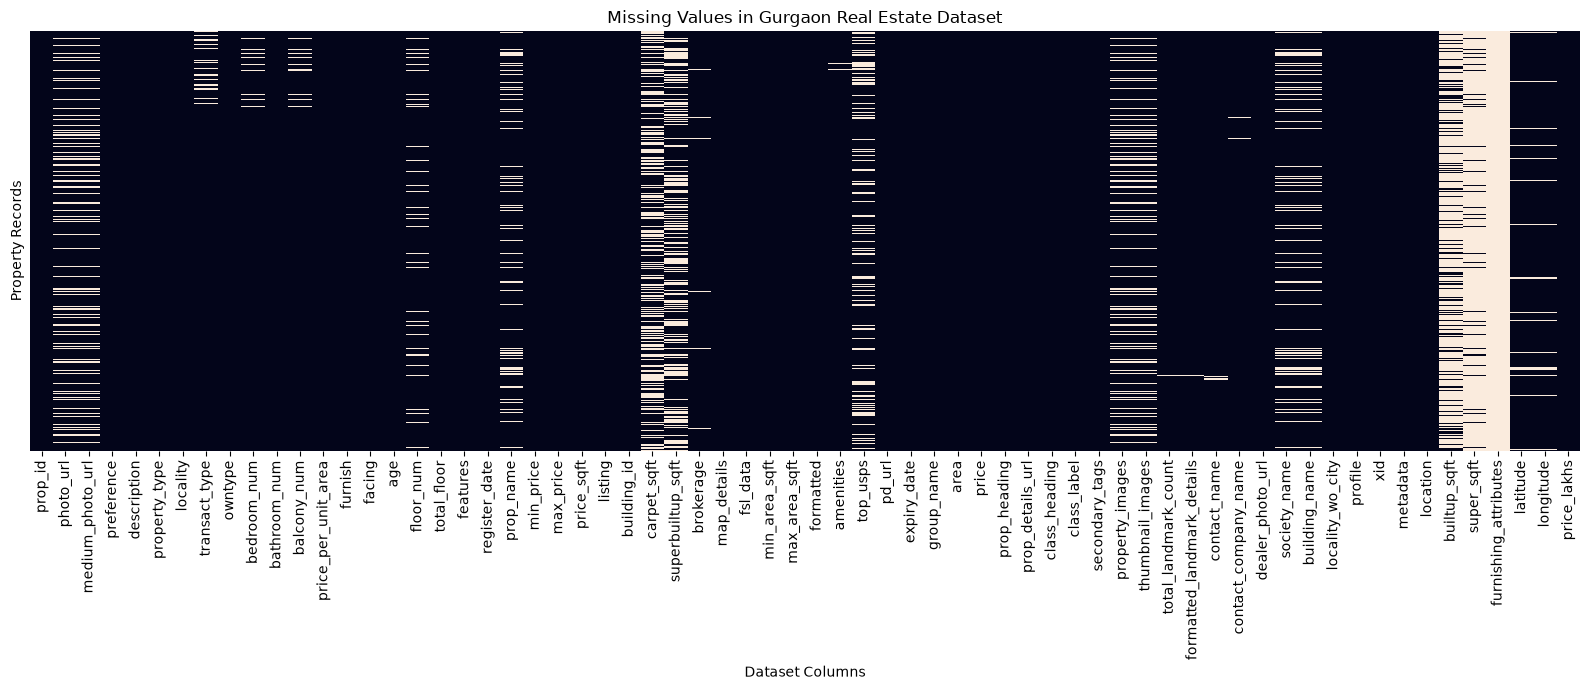

In [39]:

# Visualize missing values across the dataset

plt.figure(figsize=(16, 7))

sns.heatmap(
    df.isna(),
    cbar=False,
    yticklabels=False
)

plt.title("Missing Values in Gurgaon Real Estate Dataset")
plt.xlabel("Dataset Columns")
plt.ylabel("Property Records")
plt.xticks(rotation=90)

plt.tight_layout()
plt.show()



In [40]:
# Inspect missing values in important columns

essential_candidates = [
    "price",
    "latitude",
    "longitude",
    "area",
    "carpet_sqft",
    "builtup_sqft",
    "superbuiltup_sqft",
    "bedroom_num",
    "bathroom_num"
]

available = [col for col in essential_candidates if col in df.columns]

display(
    pd.DataFrame({
        "Missing_Count": df[available].isna().sum(),
        "Missing_Percentage": (
            df[available].isna().mean() * 100
        ).round(2)
    }).sort_values("Missing_Percentage", ascending=False)
)

,Missing_Count,Missing_Percentage
builtup_sqft,7971,74.47
carpet_sqft,4165,38.91
superbuiltup_sqft,3992,37.29
longitude,383,3.58
latitude,383,3.58
bedroom_num,193,1.80
price,0,0.00
area,0,0.00
bathroom_num,0,0.00


In [41]:
# Compare the potential row counts before deleting anything

print("Current rows:", len(df))

if "price" in df.columns:
    print(
        "Rows with price:",
        df["price"].notna().sum()
    )

if {"latitude", "longitude"}.issubset(df.columns):
    print(
        "Rows with both coordinates:",
        df[["latitude", "longitude"]].notna().all(axis=1).sum()
    )

if "builtup_sqft" in df.columns:
    print(
        "Rows with built-up area:",
        df["builtup_sqft"].notna().sum()
    )

Current rows: 10704
Rows with price: 10704
Rows with both coordinates: 10321
Rows with built-up area: 2733


In [42]:
coordinate_columns = ["latitude", "longitude"]

if all(col in df.columns for col in coordinate_columns):
    print(
        "Rows missing either coordinate:",
        df[coordinate_columns].isna().any(axis=1).sum()
    )

Rows missing either coordinate: 383


In [43]:
# Run only if coordinates are required for your selected model

rows_before = len(df)

df = df.dropna(
    subset=["latitude", "longitude"]
).copy()

rows_after = len(df)

print("Rows before:", rows_before)
print("Rows after:", rows_after)
print("Rows removed:", rows_before - rows_after)

Rows before: 10704
Rows after: 10321
Rows removed: 383


In [44]:
numeric_candidates = [
    "bedroom_num",
    "bathroom_num",
    "balcony_num",
    "age"
]

for col in numeric_candidates:
    if col in df.columns:
        print(
            f"{col}: dtype={df[col].dtype}, "
            f"missing={df[col].isna().sum()}"
        )

bedroom_num: dtype=float64, missing=187
bathroom_num: dtype=int64, missing=0
balcony_num: dtype=float64, missing=197
age: dtype=int64, missing=0


In [45]:
# Fill missing values in selected numeric features

for col in numeric_candidates:
    if col in df.columns and pd.api.types.is_numeric_dtype(df[col]):
        if df[col].notna().any():
            df[col] = df[col].fillna(df[col].median())

print("Numeric missing-value handling completed.")

Numeric missing-value handling completed.


In [46]:
# Fill missing values in selected categorical features

categorical_candidates = [
    "property_type",
    "locality",
    "furnish",
    "facing",
    "preference"
]

for col in categorical_candidates:
    if col in df.columns:
        df[col] = df[col].fillna("Unknown")

print("Categorical missing-value handling completed.")

Categorical missing-value handling completed.


In [47]:
display(pd.DataFrame(preprocessing_log))

,Step,Rows before,Rows after,Rows removed
0,Raw,10704,10704,0
1,Remove duplicate records,10704,10704,0
2,Standardize columns and remove constant columns,10704,10704,0
3,Remove exact duplicates,10704,10704,0


In [48]:
Path("../reports").mkdir(parents=True, exist_ok=True)

pd.DataFrame(preprocessing_log).to_csv(
    "../reports/preprocessing_log.csv",
    index=False
)

In [49]:
print("Dataset shape after missing-value handling:", df.shape)

print("\nRemaining missing values in important columns:")

important_columns = [
    "price_lakhs",
    "latitude",
    "longitude",
    "bedroom_num",
    "bathroom_num",
    "carpet_sqft",
    "builtup_sqft",
    "superbuiltup_sqft"
]

available_columns = [
    col for col in important_columns if col in df.columns
]

display(df[available_columns].isna().sum().to_frame(
    name="Remaining Missing Values"
))

Dataset shape after missing-value handling: (10321, 66)

Remaining missing values in important columns:


,Remaining Missing Values
price_lakhs,27
latitude,0
longitude,0
bedroom_num,0
bathroom_num,0
carpet_sqft,4005
builtup_sqft,7653
superbuiltup_sqft,3789


In [50]:
# Inspect columns relevant to outlier detection

candidate_columns = [
    "price", "price_lakhs", "transact_type",
    "bedroom_num", "bathroom_num", "locality",
    "latitude", "longitude", "area",
    "carpet_sqft", "builtup_sqft", "superbuiltup_sqft",
    "price_per_unit_area"
]

for col in candidate_columns:
    if col in df.columns:
        print(f"\n{col}")
        print("Data type:", df[col].dtype)
        print("Missing:", df[col].isna().sum())
        print("Examples:", df[col].dropna().head(5).tolist())


price
Data type: str
Missing: 0
Examples: ['2.63 Cr', '3.6 Cr', '85,000', '3.85 Cr', '40,000']

price_lakhs
Data type: float64
Missing: 27
Examples: [263.0, 360.0, 0.85, 385.0, 0.4]

transact_type
Data type: float64
Missing: 543
Examples: [1.0, 1.0, 1.0, 1.0, 1.0]

bedroom_num
Data type: float64
Missing: 0
Examples: [4.0, 4.0, 3.0, 3.0, 3.0]

bathroom_num
Data type: int64
Missing: 0
Examples: [4, 4, 3, 3, 4]

locality
Data type: str
Missing: 0
Examples: ['Sector 84 Gurgaon', 'Sector 81 Gurgaon', 'Sector 66 Gurgaon', 'Sector 112 Gurgaon', 'Sector 104 Gurgaon']

latitude
Data type: float64
Missing: 0
Examples: [28.4035469, 28.3873647, 28.3974292, 28.5203402, 28.4795324]

longitude
Data type: float64
Missing: 0
Examples: [76.9677894, 76.9475835, 77.0538823, 77.0188612, 76.9937197]

area
Data type: str
Missing: 0
Examples: ['3434 sq.ft.', '2870 sq.ft.', '1950 sq.ft.', '2802 sq.ft.', '2290 sq.ft.']

carpet_sqft
Data type: float64
Missing: 4005
Examples: [3000.0, 1700.0, 1450.0, 3080.0, 145

In [51]:
# Calculate price per square foot for analysis only

if {"price_lakhs", "builtup_sqft"}.issubset(df.columns):

    valid_area = df["builtup_sqft"] > 0

    df["price_per_sqft"] = np.nan

    df.loc[valid_area, "price_per_sqft"] = (
        df.loc[valid_area, "price_lakhs"] * 100000
        / df.loc[valid_area, "builtup_sqft"]
    )

    print("Price-per-square-foot helper created.")

    display(
        df[["price_lakhs", "builtup_sqft", "price_per_sqft"]].head(10)
    )
else:
    print("Required columns are missing. Check the column names first.")

Price-per-square-foot helper created.


,price_lakhs,builtup_sqft,price_per_sqft
0,263.00,NaN,NaN
1,360.00,NaN,NaN
2,0.85,1920.00,44.270833
3,385.00,2225.56,17299.016877
4,0.40,NaN,NaN
5,195.00,NaN,NaN
6,0.45,NaN,NaN
7,162.00,NaN,NaN
8,217.00,NaN,NaN
9,220.00,NaN,NaN


In [52]:
# Summary statistics for important numerical features

numeric_columns = [
    "price_lakhs",
    "bedroom_num",
    "bathroom_num",
    "builtup_sqft",
    "superbuiltup_sqft",
    "carpet_sqft",
    "price_per_sqft"
]

available_numeric = [
    col for col in numeric_columns
    if col in df.columns
]

display(df[available_numeric].describe().T)

,count,mean,std,min,25%,50%,75%,max
price_lakhs,10294.0,320.358987,562.443875,0.100000,136.000000,216.000000,372.750000,2.900000e+04
bedroom_num,10321.0,3.318574,1.274547,1.000000,3.000000,3.000000,4.000000,2.200000e+01
bathroom_num,10321.0,3.486968,1.518315,0.000000,3.000000,3.000000,4.000000,2.200000e+01
builtup_sqft,2668.0,2342.367057,2912.517088,0.000000,1500.000000,1900.000000,2600.000000,6.750000e+04
superbuiltup_sqft,6532.0,2368.272560,3426.063813,0.000000,1623.750000,2050.000000,2700.000000,2.588790e+05
carpet_sqft,6316.0,2499.291955,16998.842838,0.000000,1200.000000,1650.000000,2340.000000,5.779460e+05
price_per_sqft,2664.0,12292.684896,24803.962161,14.166667,8333.333333,11145.853702,14335.062873,1.193416e+06


In [53]:
if "builtup_sqft" in df.columns:

    suspicious_area = df[
        df["builtup_sqft"].notna()
        & (
            (df["builtup_sqft"] < 300)
            | (df["builtup_sqft"] > 10000)
        )
    ]

    print("Potentially suspicious area records:", len(suspicious_area))

    display(
        suspicious_area[
            [
                col for col in [
                    "locality", "property_type",
                    "bedroom_num", "builtup_sqft", "price_lakhs"
                ]
                if col in df.columns
            ]
        ].head(20)
    )

Potentially suspicious area records: 31


,locality,property_type,bedroom_num,builtup_sqft,price_lakhs
517,DLF Phase 5,Independent/Builder Floor,3.0,299.0,435.0
805,Sushant Lok Phase 3,Independent/Builder Floor,4.0,24300.0,210.0
854,Sector 109 Gurgaon,Independent House/Villa,5.0,65970.0,1000.0
891,Sushant Lok Phase 1,Independent House/Villa,5.0,27450.0,795.0
1370,Sector 50 Gurgaon,Independent/Builder Floor,3.0,241.0,0.4
2054,Sector 56 Gurgaon,Independent House/Villa,12.0,67500.0,835.0
2721,Palam Vihar,Independent/Builder Floor,3.0,14013.0,230.0
2722,Palam Vihar,Independent House/Villa,5.0,37800.0,760.0
2724,Palam Vihar,Independent House/Villa,4.0,14013.0,510.0
2765,Sector 47 Gurgaon,Independent/Builder Floor,3.0,291.0,160.0


In [54]:
if {"bedroom_num", "bathroom_num"}.issubset(df.columns):

    suspicious_bathrooms = df[
        df["bedroom_num"].notna()
        & df["bathroom_num"].notna()
        & (
            (df["bedroom_num"] < 0)
            | (df["bathroom_num"] < 0)
            | (df["bathroom_num"] > df["bedroom_num"] + 2)
        )
    ]

    print(
        "Potentially inconsistent bedroom/bathroom records:",
        len(suspicious_bathrooms)
    )

    display(
        suspicious_bathrooms[
            [
                col for col in [
                    "locality", "bedroom_num",
                    "bathroom_num", "builtup_sqft", "price_lakhs"
                ]
                if col in df.columns
            ]
        ].head(20)
    )

Potentially inconsistent bedroom/bathroom records: 27


,locality,bedroom_num,bathroom_num,builtup_sqft,price_lakhs
558,Sector 56 Gurgaon,6.0,9,NaN,749.0
1730,Sector 28 Gurgaon,5.0,8,4950.0,550.0
2665,Sector 59 Gurgaon,3.0,6,2000.0,590.0
2686,Sector 42 Gurgaon,4.0,8,NaN,4900.0
2701,Sector 42 Gurgaon,4.0,7,NaN,NaN
2764,Sector 112 Gurgaon,4.0,7,4050.0,575.0
2872,Sector 59 Gurgaon,3.0,6,NaN,560.0
4430,Sector 33 Gurgaon,5.0,8,NaN,NaN
5134,Sector 103 Gurgaon,4.0,7,NaN,300.0
5281,Sector 42 Gurgaon,4.0,7,NaN,2355.0


In [55]:
rows_before = len(df)

if "builtup_sqft" in df.columns:
    df = df[
        df["builtup_sqft"].isna()
        | (df["builtup_sqft"] > 0)
    ].copy()

rows_after = len(df)

print("Rows before:", rows_before)
print("Rows after:", rows_after)
print("Rows removed:", rows_before - rows_after)

Rows before: 10321
Rows after: 10319
Rows removed: 2


In [56]:
# Identify price-per-square-foot outliers within each locality

if {"locality", "price_per_sqft"}.issubset(df.columns):

    locality_counts = df.groupby("locality")["price_per_sqft"].transform(
        lambda s: s.notna().sum()
    )

    locality_q1 = df.groupby("locality")["price_per_sqft"].transform(
        lambda s: s.quantile(0.25)
    )

    locality_q3 = df.groupby("locality")["price_per_sqft"].transform(
        lambda s: s.quantile(0.75)
    )

    locality_iqr = locality_q3 - locality_q1

    lower_bound = locality_q1 - 1.5 * locality_iqr
    upper_bound = locality_q3 + 1.5 * locality_iqr

    outlier_mask = (
        df["price_per_sqft"].notna()
        & (locality_counts >= 5)
        & (
            (df["price_per_sqft"] < lower_bound)
            | (df["price_per_sqft"] > upper_bound)
        )
    )

    print("Potential price-per-square-foot outliers:", outlier_mask.sum())

    display(
        df.loc[
            outlier_mask,
            [
                col for col in [
                    "locality", "price_lakhs",
                    "builtup_sqft", "price_per_sqft"
                ]
                if col in df.columns
            ]
        ].head(20)
    )

Potential price-per-square-foot outliers: 249


,locality,price_lakhs,builtup_sqft,price_per_sqft
2,Sector 66 Gurgaon,0.85,1920.0,44.270833
13,Sector 66 Gurgaon,0.70,1920.0,36.458333
98,DLF Phase 5,0.80,1750.0,45.714286
104,DLF Phase 5,0.75,1675.0,44.776119
105,DLF Phase 5,0.70,1672.0,41.866029
161,Sector 66 Gurgaon,0.65,1920.0,33.854167
174,Sector 66 Gurgaon,0.72,1920.0,37.500000
176,Sector-33 Sohna,0.45,1750.0,25.714286
177,Sector-33 Sohna,0.58,2500.0,23.200000
178,Sector 48 Gurgaon,0.86,2500.0,34.400000


In [57]:
# Check global price outliers

if "price_lakhs" in df.columns:

    valid_prices = df["price_lakhs"].dropna()

    q1, q3 = valid_prices.quantile([0.25, 0.75])
    iqr = q3 - q1

    lower_bound = q1 - 1.5 * iqr
    upper_bound = q3 + 1.5 * iqr

    outliers = (
        (df["price_lakhs"] < lower_bound)
        | (df["price_lakhs"] > upper_bound)
    )

    print(f"Lower IQR bound: {lower_bound:.2f} lakhs")
    print(f"Upper IQR bound: {upper_bound:.2f} lakhs")
    print("Rows outside IQR bounds:", outliers.sum())

Lower IQR bound: -219.88 lakhs
Upper IQR bound: 729.12 lakhs
Rows outside IQR bounds: 693


In [58]:
if "price_lakhs" in df.columns:
    df["log_price"] = np.log1p(df["price_lakhs"])

    print("Original price distribution:")
    print(df["price_lakhs"].describe())

    print("\nLog-transformed price distribution:")
    print(df["log_price"].describe())

Original price distribution:
count    10292.000000
mean       320.385679
std        562.495265
min          0.100000
25%        136.000000
50%        216.000000
75%        373.250000
max      29000.000000
Name: price_lakhs, dtype: float64

Log-transformed price distribution:
count    10292.000000
mean         5.208471
std          1.350340
min          0.095310
25%          4.919981
50%          5.379897
75%          5.924923
max         10.275086
Name: log_price, dtype: float64


In [59]:
df_before_outliers = df.copy()

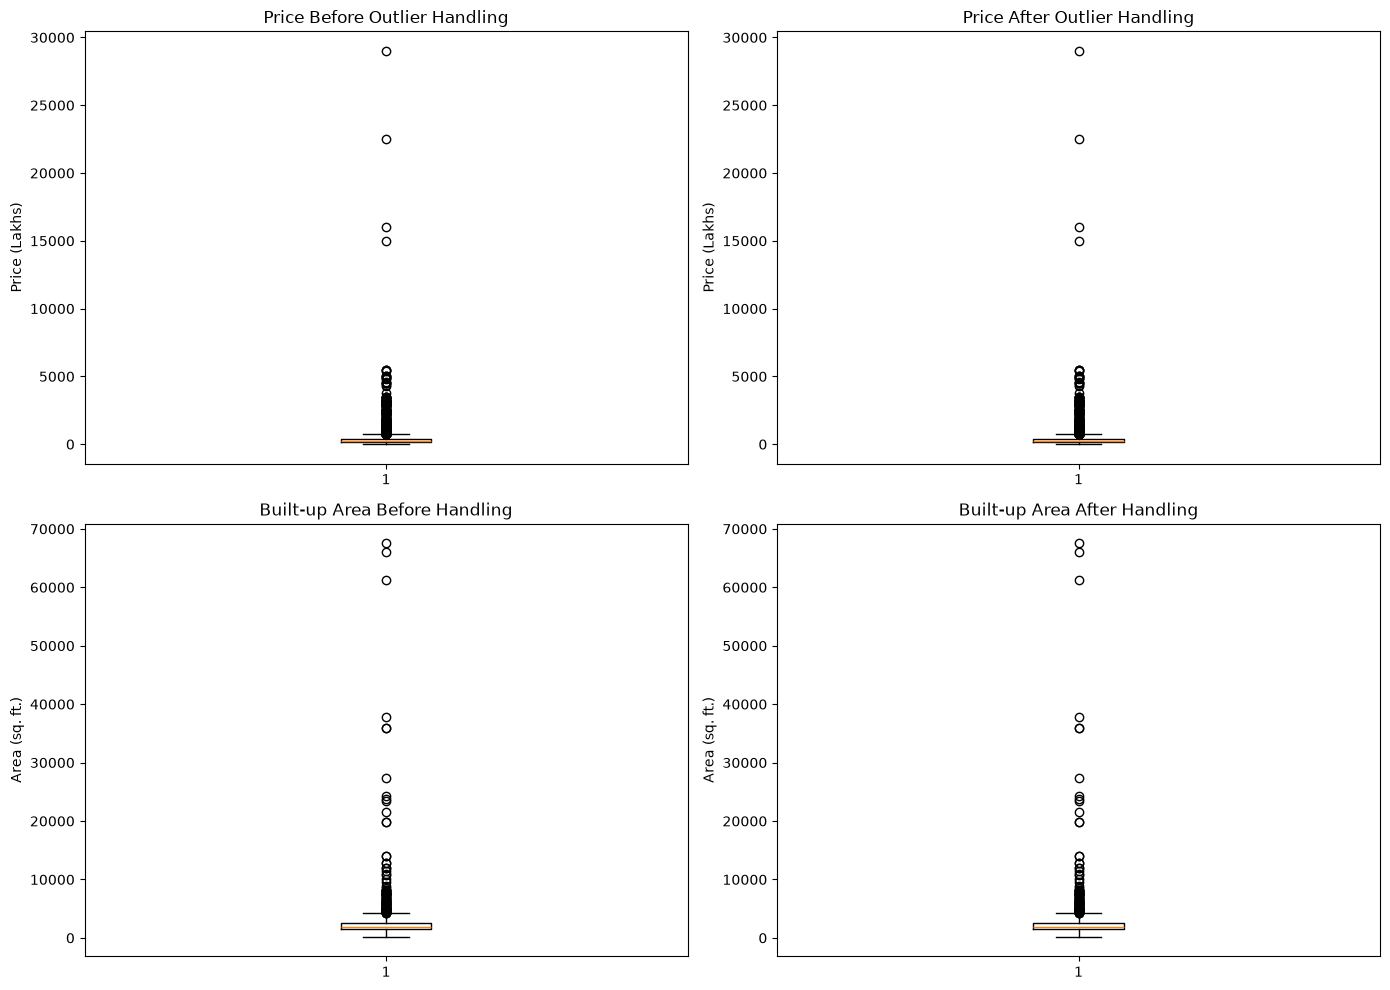

In [60]:
# Compare distributions before and after outlier handling

fig, axes = plt.subplots(2, 2, figsize=(14, 10))

axes[0, 0].boxplot(
    df_before_outliers["price_lakhs"].dropna()
)
axes[0, 0].set_title("Price Before Outlier Handling")
axes[0, 0].set_ylabel("Price (Lakhs)")

axes[0, 1].boxplot(
    df["price_lakhs"].dropna()
)
axes[0, 1].set_title("Price After Outlier Handling")
axes[0, 1].set_ylabel("Price (Lakhs)")

if "builtup_sqft" in df.columns:
    axes[1, 0].boxplot(
        df_before_outliers["builtup_sqft"].dropna()
    )
    axes[1, 0].set_title("Built-up Area Before Handling")
    axes[1, 0].set_ylabel("Area (sq. ft.)")

    axes[1, 1].boxplot(
        df["builtup_sqft"].dropna()
    )
    axes[1, 1].set_title("Built-up Area After Handling")
    axes[1, 1].set_ylabel("Area (sq. ft.)")

plt.tight_layout()
plt.show()

In [61]:

# Check whether the locality column exists
if "locality" in df.columns:

    loc_counts = df["locality"].value_counts(dropna=False)

    print("Total property records:", len(df))
    print("Unique locality values:", df["locality"].nunique())
    print("\nTop 20 localities by listing count:")

    display(loc_counts.head(20).to_frame(name="Listing_Count"))

else:
    print("Column 'locality' not found.")
    print("Available columns:", df.columns.tolist())



Total property records: 10319
Unique locality values: 189

Top 20 localities by listing count:


,Listing_Count
locality,
Sector 65 Gurgaon,358
Sector 102 Gurgaon,288
Sector 48 Gurgaon,275
Sector 54 Gurgaon,273
DLF Phase 2,269
Sohna,240
DLF Phase 1,233
Sector-33 Sohna,220
Sector 67 Gurgaon,219


In [62]:

# Count listings per locality
loc_counts = df["locality"].value_counts()

# Identify localities with fewer than 10 listings
rare_localities = loc_counts[loc_counts < 10].index

# Preserve the original locality column
df["locality_grouped"] = df["locality"].where(
    ~df["locality"].isin(rare_localities),
    "Other"
)

# Handle missing locality values separately
df["locality_grouped"] = df["locality_grouped"].fillna("Unknown")

print("Original unique localities:", df["locality"].nunique())
print("Rare localities grouped:", len(rare_localities))
print("Localities after grouping:", df["locality_grouped"].nunique())

print("\nListing counts after grouping:")
display(
    df["locality_grouped"]
    .value_counts()
    .head(20)
    .to_frame(name="Listing_Count")
)



Original unique localities: 189
Rare localities grouped: 79
Localities after grouping: 111

Listing counts after grouping:


,Listing_Count
locality_grouped,
Sector 65 Gurgaon,358
Sector 102 Gurgaon,288
Sector 48 Gurgaon,275
Sector 54 Gurgaon,273
DLF Phase 2,269
Sohna,240
DLF Phase 1,233
Sector-33 Sohna,220
Sector 67 Gurgaon,219


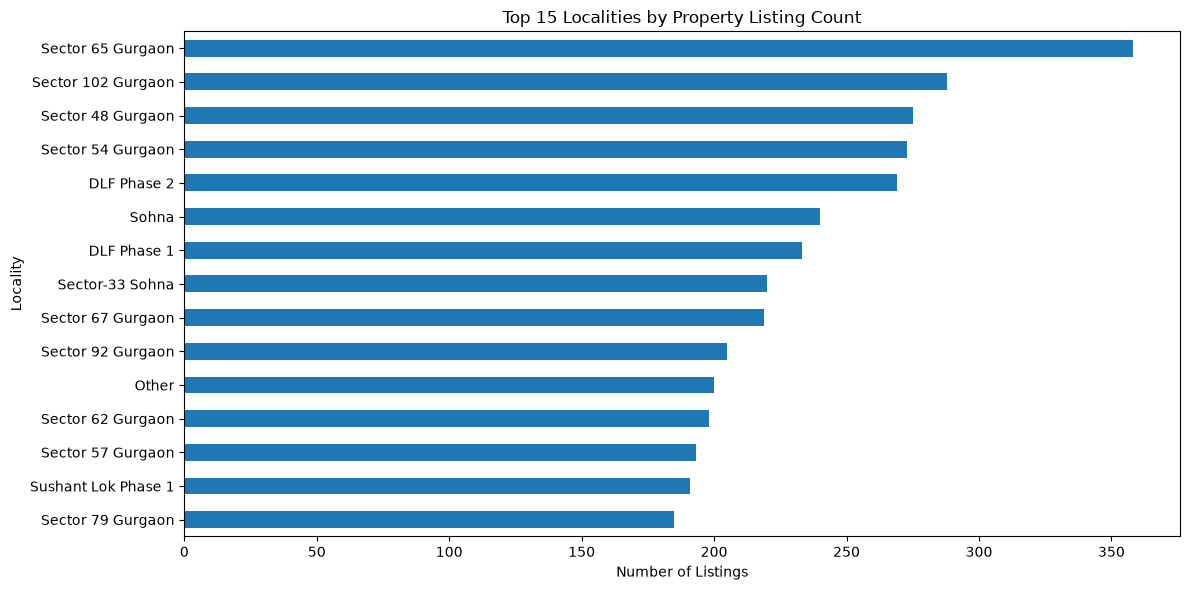

In [63]:
# Plot the 15 most common grouped localities

plt.figure(figsize=(12, 6))

df["locality_grouped"].value_counts().head(15).sort_values().plot(
    kind="barh"
)

plt.title("Top 15 Localities by Property Listing Count")
plt.xlabel("Number of Listings")
plt.ylabel("Locality")

plt.tight_layout()
plt.show()

In [64]:
print("Original dataset shape:", df_raw.shape)
print("Current dataset shape:", df.shape)

print(
    "Missing original localities:",
    df["locality"].isna().sum()
)

print(
    "Missing grouped localities:",
    df["locality_grouped"].isna().sum()
)

Original dataset shape: (10704, 69)
Current dataset shape: (10319, 69)
Missing original localities: 0
Missing grouped localities: 0


In [65]:
preprocessing_log.append({
    "Step": "Group rare localities",
    "Rows before": len(df),
    "Rows after": len(df),
    "Rows removed": 0
})

display(pd.DataFrame(preprocessing_log))

,Step,Rows before,Rows after,Rows removed
0,Raw,10704,10704,0
1,Remove duplicate records,10704,10704,0
2,Standardize columns and remove constant columns,10704,10704,0
3,Remove exact duplicates,10704,10704,0
4,Group rare localities,10319,10319,0


In [66]:
# Identify categorical columns
categorical_columns = df.select_dtypes(
    include=["object", "category", "string"]
).columns.tolist()

print("Number of categorical columns:", len(categorical_columns))
print("\nCategorical columns:")
print(categorical_columns)

Number of categorical columns: 42

Categorical columns:
['prop_id', 'photo_url', 'medium_photo_url', 'preference', 'description', 'property_type', 'locality', 'floor_num', 'features', 'register_date', 'prop_name', 'listing', 'map_details', 'fsl_data', 'formatted', 'amenities', 'top_usps', 'pd_url', 'expiry_date', 'group_name', 'area', 'price', 'prop_heading', 'prop_details_url', 'class_heading', 'class_label', 'secondary_tags', 'property_images', 'thumbnail_images', 'formatted_landmark_details', 'contact_name', 'contact_company_name', 'dealer_photo_url', 'society_name', 'building_name', 'locality_wo_city', 'profile', 'xid', 'metadata', 'location', 'furnishing_attributes', 'locality_grouped']


In [67]:
# Inspect important categorical columns that exist in the dataset
candidate_columns = [
    "property_type",
    "transact_type",
    "locality",
    "locality_grouped",
    "furnish",
    "facing",
    "preference",
    "res_com"
]

for col in candidate_columns:
    if col in df.columns:
        print(f"\n--- {col} ---")
        print("Unique values:", df[col].nunique(dropna=True))
        display(df[col].value_counts(dropna=False).head(15).to_frame("Count"))


--- property_type ---
Unique values: 4


,Count
property_type,
Residential Apartment,6821
Independent/Builder Floor,2661
Independent House/Villa,660
Residential Land,177



--- transact_type ---
Unique values: 2


,Count
transact_type,
1.0,9764
NaN,543
2.0,12



--- locality ---
Unique values: 189


...

,Count
furnish,
4,7600
2,1477
1,761
0,481



--- facing ---
Unique values: 9


,Count
facing,
5,3575
3,2386
1,1442
0,1138
4,606
7,362
6,356
2,242
8,212



--- preference ---
Unique values: 2


,Count
preference,
S,9779
R,540


In [68]:
# Verify that categorical values are still available
print("Locality column exists:", "locality" in df.columns)
print("Grouped locality column exists:", "locality_grouped" in df.columns)

if "locality_grouped" in df.columns:
    print("\nGrouped locality categories:")
    print(df["locality_grouped"].nunique(dropna=False))

print("\nCurrent dataset shape:", df.shape)

Locality column exists: True
Grouped locality column exists: True

Grouped locality categories:
111

Current dataset shape: (10319, 69)


In [69]:
preprocessing_log.append({
    "Step": "Prepare categorical variables for pipeline encoding",
    "Rows before": len(df),
    "Rows after": len(df),
    "Rows removed": 0
})

print("Categorical preparation completed.")
print("Current dataset shape:", df.shape)

Categorical preparation completed.
Current dataset shape: (10319, 69)


In [70]:
from pathlib import Path

output_dir = Path("../data/processed")
output_dir.mkdir(parents=True, exist_ok=True)

df.to_csv(output_dir / "housing_preprocessed.csv", index=False)

print("Saved to:", output_dir / "housing_preprocessed.csv")
print("Final shape:", df.shape)

Saved to: ..\data\processed\housing_preprocessed.csv
Final shape: (10319, 69)


In [71]:
# Identify numerical columns
numeric_columns = df.select_dtypes(include=["number"]).columns.tolist()

print("Number of numerical columns:", len(numeric_columns))
print("\nNumerical columns:")
print(numeric_columns)

Number of numerical columns: 27

Numerical columns:
['transact_type', 'owntype', 'bedroom_num', 'bathroom_num', 'balcony_num', 'price_per_unit_area', 'furnish', 'facing', 'age', 'total_floor', 'min_price', 'max_price', 'price_sqft', 'building_id', 'carpet_sqft', 'superbuiltup_sqft', 'brokerage', 'min_area_sqft', 'max_area_sqft', 'total_landmark_count', 'builtup_sqft', 'super_sqft', 'latitude', 'longitude', 'price_lakhs', 'price_per_sqft', 'log_price']


In [72]:
# Inspect missing values in numerical columns
numeric_missing = df[numeric_columns].isna().sum()
numeric_missing = numeric_missing[numeric_missing > 0].sort_values(ascending=False)

print("Numerical columns with missing values:")
display(numeric_missing.to_frame(name="Missing_Count"))

Numerical columns with missing values:


,Missing_Count
super_sqft,9504
price_per_sqft,7655
builtup_sqft,7653
carpet_sqft,4005
superbuiltup_sqft,3789
transact_type,543
brokerage,80
total_landmark_count,36
price_lakhs,27
log_price,27


In [73]:
preprocessing_log.append({
    "Step": "Inspect numerical features and plan pipeline scaling",
    "Rows before": len(df),
    "Rows after": len(df),
    "Rows removed": 0
})

print("Feature-scaling preparation completed.")
print("Dataset shape:", df.shape)

Feature-scaling preparation completed.
Dataset shape: (10319, 69)


In [74]:
from pathlib import Path
import pandas as pd

# Create output directories
processed_dir = Path("../data/processed")
reports_dir = Path("../reports")

processed_dir.mkdir(parents=True, exist_ok=True)
reports_dir.mkdir(parents=True, exist_ok=True)

# Save the prepared dataset
output_file = processed_dir / "housing_preprocessed.csv"
df.to_csv(output_file, index=False)

# Save the preprocessing log
log_file = reports_dir / "preprocessing_log.csv"
pd.DataFrame(preprocessing_log).to_csv(log_file, index=False)

print("Prepared dataset saved successfully!")
print("Dataset path:", output_file.resolve())
print("Preprocessing log:", log_file.resolve())
print("Dataset shape:", df.shape)
print("Total rows:", len(df))
print("Total columns:", len(df.columns))

Prepared dataset saved successfully!
Dataset path: D:\real-estate-price-prediction\data\processed\housing_preprocessed.csv
Preprocessing log: D:\real-estate-price-prediction\reports\preprocessing_log.csv
Dataset shape: (10319, 69)
Total rows: 10319
Total columns: 69


In [75]:
# Count properties at different price levels

price_checks = {
    "Below ₹10 lakh": df["price_lakhs"] < 10,
    "₹10–50 lakh": df["price_lakhs"].between(10, 50, inclusive="left"),
    "₹50 lakh–₹1 crore": df["price_lakhs"].between(50, 100, inclusive="left"),
    "₹1–5 crore": df["price_lakhs"].between(100, 500, inclusive="left"),
    "₹5–10 crore": df["price_lakhs"].between(500, 1000, inclusive="left"),
    "Above ₹10 crore": df["price_lakhs"] >= 1000,
}

for label, condition in price_checks.items():
    print(f"{label}: {condition.sum():,} listings")

Below ₹10 lakh: 546 listings
₹10–50 lakh: 327 listings
₹50 lakh–₹1 crore: 698 listings
₹1–5 crore: 7,134 listings
₹5–10 crore: 1,201 listings
Above ₹10 crore: 386 listings


In [76]:
# Inspect the 30 most expensive properties

columns_to_inspect = [
    "price",
    "price_lakhs",
    "property_type",
    "bedroom_num",
    "bathroom_num",
    "carpet_sqft",
    "builtup_sqft",
    "superbuiltup_sqft",
    "locality_grouped",
]

columns_to_inspect = [
    col for col in columns_to_inspect
    if col in df.columns
]

display(
    df.nlargest(30, "price_lakhs")[columns_to_inspect]
)

,price,price_lakhs,property_type,bedroom_num,bathroom_num,carpet_sqft,builtup_sqft,superbuiltup_sqft,locality_grouped
9209,290 Cr,29000.0,Independent/Builder Floor,4.0,4,1400.0,2430.0,NaN,DLF Phase 3
4952,225 Cr,22500.0,Independent/Builder Floor,4.0,4,1890.0,NaN,NaN,Sector 92 Gurgaon
1320,160 Cr,16000.0,Residential Land,3.0,0,NaN,NaN,NaN,Sohna
632,150 Cr,15000.0,Residential Apartment,10.0,11,NaN,NaN,17000.0,Sector 42 Gurgaon
2682,55 Cr,5500.0,Residential Apartment,5.0,6,NaN,NaN,11500.0,Sector 42 Gurgaon
5492,55 Cr,5500.0,Residential Apartment,4.0,8,NaN,NaN,7400.0,Sector 42 Gurgaon
5805,55 Cr,5500.0,Residential Apartment,4.0,4,7400.0,NaN,NaN,Sector 42 Gurgaon
7657,54 Cr,5400.0,Residential Apartment,4.0,4,NaN,2600.0,3395.0,Sector 106 Gurgaon
4211,50 Cr,5000.0,Residential Apartment,4.0,4,NaN,NaN,7369.0,Sector 42 Gurgaon
8880,50 Cr,5000.0,Residential Apartment,5.0,6,NaN,10800.0,NaN,Sector 42 Gurgaon


In [77]:
area_columns = [
    "carpet_sqft",
    "builtup_sqft",
    "superbuiltup_sqft",
]

area_columns = [
    col for col in area_columns
    if col in df.columns
]

print("Area column statistics:")

display(df[area_columns].describe().T)

print("\nMissing area values:")

display(df[area_columns].isna().sum().to_frame("Missing Count"))

print("\nNon-positive area values:")

for col in area_columns:
    numeric_values = pd.to_numeric(df[col], errors="coerce")
    print(f"{col}: {(numeric_values <= 0).sum():,}")

Area column statistics:


,count,mean,std,min,25%,50%,75%,max
carpet_sqft,6314.0,2500.083622,17001.477080,30.0,1200.0,1650.0,2340.0,577946.0
builtup_sqft,2666.0,2344.124271,2912.902532,200.0,1500.0,1900.0,2600.0,67500.0
superbuiltup_sqft,6530.0,2368.997912,3426.337732,242.0,1625.0,2050.0,2700.0,258879.0



Missing area values:


,Missing Count
carpet_sqft,4005
builtup_sqft,7653
superbuiltup_sqft,3789



Non-positive area values:
carpet_sqft: 0
builtup_sqft: 0
superbuiltup_sqft: 0


In [78]:
# 1. Dataset shape
print("Dataset shape:", df.shape)

# 2. Missing values
print("\nTotal missing values:", df.isna().sum().sum())

# 3. Duplicate rows
print("Duplicate rows:", df.duplicated().sum())

# 4. Data types
print("\nColumn data types:")
print(df.dtypes)

# 5. Numerical statistics
print("\nNumerical column statistics:")
display(df.describe().T)

# 6. Target validation
print("\nTarget price statistics:")
print(df["price_lakhs"].describe())

print("\nInvalid target prices:",
      ((df["price_lakhs"].isna()) |
       (df["price_lakhs"] <= 0)).sum())

Dataset shape: (10319, 69)

Total missing values: 58640
Duplicate rows: 0

Column data types:
prop_id                 str
photo_url               str
medium_photo_url        str
preference              str
description             str
                     ...   
longitude           float64
price_lakhs         float64
price_per_sqft      float64
log_price           float64
locality_grouped        str
Length: 69, dtype: object

Numerical column statistics:


,count,mean,std,min,25%,50%,75%,max
transact_type,9776.0,1.001227e+00,3.501592e-02,1.000000,1.000000e+00,1.000000e+00,1.000000e+00,2.000000e+00
owntype,10319.0,9.667603e-01,3.017682e-01,0.000000,1.000000e+00,1.000000e+00,1.000000e+00,4.000000e+00
bedroom_num,10319.0,3.317279e+00,1.271271e+00,1.000000,3.000000e+00,3.000000e+00,4.000000e+00,2.200000e+01
bathroom_num,10319.0,3.485706e+00,1.515752e+00,0.000000,3.000000e+00,3.000000e+00,4.000000e+00,2.200000e+01
balcony_num,10319.0,2.938075e+00,9.093125e-01,0.000000,2.000000e+00,3.000000e+00,4.000000e+00,4.000000e+00
price_per_unit_area,10319.0,4.743856e+04,9.189322e+05,0.000000,8.308500e+03,1.176600e+04,1.750200e+04,8.500000e+07
furnish,10319.0,3.306037e+00,1.225003e+00,0.000000,2.000000e+00,4.000000e+00,4.000000e+00,4.000000e+00
facing,10319.0,3.464386e+00,2.046860e+00,0.000000,1.500000e+00,3.000000e+00,5.000000e+00,8.000000e+00
age,10319.0,3.204962e+00,2.154291e+00,0.000000,1.000000e+00,2.000000e+00,6.000000e+00,6.000000e+00
total_floor,10313.0,1.482847e+01,1.130737e+01,0.000000,4.000000e+00,1.400000e+01,2.200000e+01,5.100000e+01



Target price statistics:
count    10292.000000
mean       320.385679
std        562.495265
min          0.100000
25%        136.000000
50%        216.000000
75%        373.250000
max      29000.000000
Name: price_lakhs, dtype: float64

Invalid target prices: 27


In [79]:
# Keep a separate copy for exploratory data analysis
df_eda = df.copy()

# Columns that must not be used as model input features
leakage_columns = [
    "price",
    "price_per_sqft",
    "price_per_unit_area",
    "price_sqft",
    "min_price",
    "max_price",
    "log_price"
]

# Remove only columns that exist
columns_to_drop = [
    col for col in leakage_columns
    if col in df.columns
]

df_model = df.drop(columns=columns_to_drop).copy()

print("EDA dataset shape:", df_eda.shape)
print("Model dataset shape:", df_model.shape)

print("\nRemoved columns:")
print(columns_to_drop)

print("\nRemaining columns:")
print(df_model.columns.tolist())

EDA dataset shape: (10319, 69)
Model dataset shape: (10319, 62)

Removed columns:
['price', 'price_per_sqft', 'price_per_unit_area', 'price_sqft', 'min_price', 'max_price', 'log_price']

Remaining columns:
['prop_id', 'photo_url', 'medium_photo_url', 'preference', 'description', 'property_type', 'locality', 'transact_type', 'owntype', 'bedroom_num', 'bathroom_num', 'balcony_num', 'furnish', 'facing', 'age', 'floor_num', 'total_floor', 'features', 'register_date', 'prop_name', 'listing', 'building_id', 'carpet_sqft', 'superbuiltup_sqft', 'brokerage', 'map_details', 'fsl_data', 'min_area_sqft', 'max_area_sqft', 'formatted', 'amenities', 'top_usps', 'pd_url', 'expiry_date', 'group_name', 'area', 'prop_heading', 'prop_details_url', 'class_heading', 'class_label', 'secondary_tags', 'property_images', 'thumbnail_images', 'total_landmark_count', 'formatted_landmark_details', 'contact_name', 'contact_company_name', 'dealer_photo_url', 'society_name', 'building_name', 'locality_wo_city', 'profi

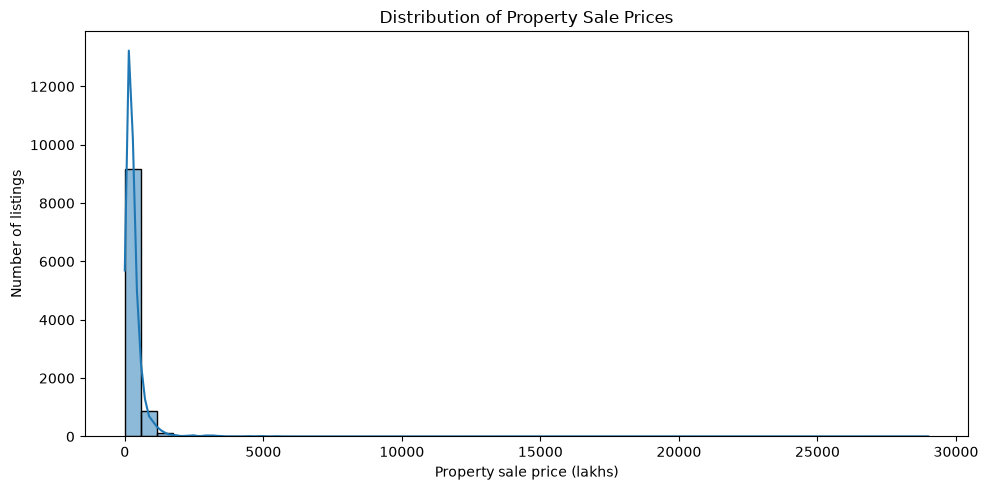

Price skewness: 24.398


In [80]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# Ensure target is numeric
df_model["price_lakhs"] = pd.to_numeric(
    df_model["price_lakhs"],
    errors="coerce"
)

# Remove rows with invalid targets, if any
df_model = df_model[
    df_model["price_lakhs"].notna() &
    (df_model["price_lakhs"] > 0)
].copy()

# Plot original target distribution
plt.figure(figsize=(10, 5))
sns.histplot(df_model["price_lakhs"], bins=50, kde=True)

plt.xlabel("Property sale price (lakhs)")
plt.ylabel("Number of listings")
plt.title("Distribution of Property Sale Prices")

plt.tight_layout()
plt.show()

# Calculate skewness
price_skew = df_model["price_lakhs"].skew()

print("Price skewness:", round(price_skew, 3))

In [81]:
df_model["log_price_target"] = np.log1p(
    df_model["price_lakhs"]
)

print("Original target skewness:",
      round(df_model["price_lakhs"].skew(), 3))

print("Log-transformed target skewness:",
      round(df_model["log_price_target"].skew(), 3))

Original target skewness: 24.398
Log-transformed target skewness: -2.0


In [82]:
predicted_price_lakhs = np.expm1(predicted_log_price)

NameError: name 'predicted_log_price' is not defined

In [83]:
import numpy as np

df_model["log_price_target"] = np.log1p(
    df_model["price_lakhs"]
)

print("Original price skewness:",
      df_model["price_lakhs"].skew())

print("Log-transformed price skewness:",
      df_model["log_price_target"].skew())

Original price skewness: 24.398109622589
Log-transformed price skewness: -2.0004621349009812


In [84]:
from pathlib import Path

# Create output directory
output_dir = Path("../data/processed")
output_dir.mkdir(parents=True, exist_ok=True)

# Save model-ready data
df_model.to_csv(
    output_dir / "clean.csv",
    index=False
)

# Save EDA data, including price-related columns
df_eda.to_csv(
    output_dir / "clean_with_pps.csv",
    index=False
)

print("Model-ready data saved:", (output_dir / "clean.csv").resolve())
print("EDA data saved:", (output_dir / "clean_with_pps.csv").resolve())

print("\nFinal model dataset shape:", df_model.shape)
print("Final EDA dataset shape:", df_eda.shape)

Model-ready data saved: D:\real-estate-price-prediction\data\processed\clean.csv
EDA data saved: D:\real-estate-price-prediction\data\processed\clean_with_pps.csv

Final model dataset shape: (10292, 63)
Final EDA dataset shape: (10319, 69)


In [85]:
raw_rows = len(df_raw)
processed_rows = len(df_model)

if raw_rows > 0:
    retained_percentage = round(
        processed_rows / raw_rows * 100, 1
    )
    print("Raw rows:", raw_rows)
    print("Processed rows:", processed_rows)
    print("Retained:", retained_percentage, "% of raw data")
else:
    print("Raw dataset is empty; retention cannot be calculated.")

Raw rows: 10704
Processed rows: 10292
Retained: 96.2 % of raw data


In [86]:
# Reload the saved files to verify they were written correctly
df_model_check = pd.read_csv(
    "../data/processed/clean.csv",
    low_memory=False
)

df_eda_check = pd.read_csv(
    "../data/processed/clean_with_pps.csv",
    low_memory=False
)

print("Model dataset:", df_model_check.shape)
print("EDA dataset:", df_eda_check.shape)

print("\nMissing target values:",
      df_model_check["price_lakhs"].isna().sum())

print("Invalid target values:",
      (df_model_check["price_lakhs"] <= 0).sum())

Model dataset: (10292, 63)
EDA dataset: (10319, 69)

Missing target values: 0
Invalid target values: 0


In [87]:
import pandas as pd

df_check = pd.read_csv(
    "../data/processed/clean.csv",
    low_memory=False
)

print("Shape:", df_check.shape)
print("\nFirst five rows:")
display(df_check.head())

print("\nTarget statistics:")
print(df_check["price_lakhs"].describe())

print("\nMissing target values:")
print(df_check["price_lakhs"].isna().sum())

Shape: (10128, 58)

First five rows:


,photo_url,medium_photo_url,property_type,city,locality,owntype,bedroom_num,bathroom_num,balcony_num,furnish,...,xid,metadata,location,builtup_sqft,super_sqft,common_furnishing_attributes,quality_score,furnishing_attributes,price_lakhs,locality_grouped
0,https://mediacdn.99acres.com/media1/22409/13/4...,https://mediacdn.99acres.com/media1/22409/13/4...,Residential Apartment,Gurgaon,Sector 84 Gurgaon,1,4.0,4,4.0,4,...,"{'PROJECTID': 5096, 'PROJ_NAME': 'Alpha Corp G...","{'PROP_PHOTO_COUNT': '4', 'PROP_VIDEO_COUNT': ...","{'CITY': '8', 'CITY_NAME': 'Gurgaon', 'BUILDIN...",NaN,NaN,NaN,NaN,NaN,263.0,Sector 84 Gurgaon
1,https://mediacdn.99acres.com/media1/22425/6/44...,https://mediacdn.99acres.com/media1/22425/6/44...,Residential Apartment,Gurgaon,Sector 81 Gurgaon,1,4.0,4,3.0,4,...,"{'PROJECTID': 7182, 'PROJ_NAME': 'DLF The Ulti...","{'PROP_PHOTO_COUNT': '4', 'PROP_VIDEO_COUNT': ...","{'CITY': '8', 'CITY_NAME': 'Gurgaon', 'BUILDIN...",NaN,NaN,NaN,NaN,NaN,360.0,Sector 81 Gurgaon
2,https://mediacdn.99acres.com/media1/22353/14/4...,https://mediacdn.99acres.com/media1/22353/14/4...,Residential Apartment,Gurgaon,Sector 112 Gurgaon,1,3.0,3,3.0,4,...,"{'PROJECTID': 4342, 'PROJ_NAME': 'Experion Win...","{'PROP_PHOTO_COUNT': '1', 'PROP_VIDEO_COUNT': ...","{'CITY': '8', 'CITY_NAME': 'Gurgaon', 'BUILDIN...",2225.56,NaN,NaN,NaN,NaN,385.0,Sector 112 Gurgaon
3,https://mediacdn.99acres.com/media1/22352/4/44...,https://mediacdn.99acres.com/media1/22352/4/44...,Residential Apartment,Gurgaon,Sector 104 Gurgaon,1,3.0,4,4.0,4,...,"{'PROJECTID': 25860, 'PROJ_NAME': 'ATS Triumph...","{'PROP_PHOTO_COUNT': '14', 'PROP_VIDEO_COUNT':...","{'CITY': '8', 'CITY_NAME': 'Gurgaon', 'BUILDIN...",NaN,NaN,NaN,NaN,NaN,195.0,Sector 104 Gurgaon
4,https://mediacdn.99acres.com/media1/22348/8/44...,https://mediacdn.99acres.com/media1/22348/8/44...,Residential Apartment,Gurgaon,Sector 74 Gurgaon,1,2.0,2,3.0,2,...,"{'PROJECTID': 368291, 'PROJ_NAME': 'M3M Skywal...","{'PROP_PHOTO_COUNT': '1', 'PROP_VIDEO_COUNT': ...","{'CITY': '8', 'CITY_NAME': 'Gurgaon', 'BUILDIN...",NaN,NaN,NaN,NaN,NaN,162.0,Sector 74 Gurgaon



Target statistics:
count    10128.000000
mean       336.368033
std        563.182879
min          1.000000
25%        150.000000
50%        230.000000
75%        380.000000
max      29000.000000
Name: price_lakhs, dtype: float64

Missing target values:
0


In [88]:
import pandas as pd

# Change this path if your final preprocessing uses another input file.
raw_path = "../data/raw/housing_raw.csv"

df_log = pd.read_csv(raw_path)

row_log = []

def record_step(step_name, dataframe):
    row_log.append({
        "Step": step_name,
        "Rows": len(dataframe),
        "Columns": len(dataframe.columns)
    })

record_step("1. Raw dataset", df_log)

# Standardize column names
df_log.columns = (
    df_log.columns
    .str.strip()
    .str.lower()
    .str.replace(" ", "_", regex=False)
    .str.replace("-", "_", regex=False)
)

# Clean surrounding whitespace in text columns
for col in df_log.select_dtypes(include="object").columns:
    df_log[col] = df_log[col].str.strip()

record_step("2. After standardizing columns and text", df_log)

# Remove exact duplicate rows
df_log = df_log.drop_duplicates()
record_step("3. After removing exact duplicates", df_log)

print("Columns available for target processing:")
print(df_log.columns.tolist())

C:\Users\hp\AppData\Local\Temp\ipykernel_20212\2809467017.py:6: DtypeWarning: Columns (66: FURNISHING_ATTRIBUTES) have mixed types. Specify dtype option on import or set low_memory=False.
  df_log = pd.read_csv(raw_path)
C:\Users\hp\AppData\Local\Temp\ipykernel_20212\2809467017.py:29: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  for col in df_log.select_dtypes(include="object").columns:


Columns available for target processing:
['prop_id', 'photo_url', 'medium_photo_url', 'preference', 'description', 'property_type', 'city', 'locality', 'transact_type', 'owntype', 'bedroom_num', 'bathroom_num', 'balcony_num', 'price_per_unit_area', 'furnish', 'facing', 'age', 'floor_num', 'total_floor', 'features', 'register_date', 'prop_name', 'min_price', 'max_price', 'price_sqft', 'listing', 'building_id', 'carpet_sqft', 'superbuiltup_sqft', 'brokerage', 'map_details', 'fsl_data', 'min_area_sqft', 'max_area_sqft', 'formatted', 'amenities', 'top_usps', 'pd_url', 'expiry_date', 'group_name', 'area', 'price', 'prop_heading', 'prop_details_url', 'class_heading', 'class_label', 'secondary_tags', 'property_images', 'thumbnail_images', 'total_landmark_count', 'formatted_landmark_details', 'contact_name', 'contact_company_name', 'dealer_photo_url', 'society_name', 'building_name', 'city_id', 'locality_wo_city', 'profile', 'xid', 'metadata', 'location', 'builtup_sqft', 'super_sqft', 'common_

In [89]:
import pandas as pd

df_final = pd.read_csv("../data/processed/clean.csv")

print("Final processed dataset shape:", df_final.shape)
print("Final processed dataset rows:", len(df_final))
print("Final processed dataset columns:", len(df_final.columns))

Final processed dataset shape: (10128, 58)
Final processed dataset rows: 10128
Final processed dataset columns: 58


C:\Users\hp\AppData\Local\Temp\ipykernel_20212\2492034270.py:8: DtypeWarning: Columns (66: FURNISHING_ATTRIBUTES) have mixed types. Specify dtype option on import or set low_memory=False.
  df_before = pd.read_csv(raw_path)


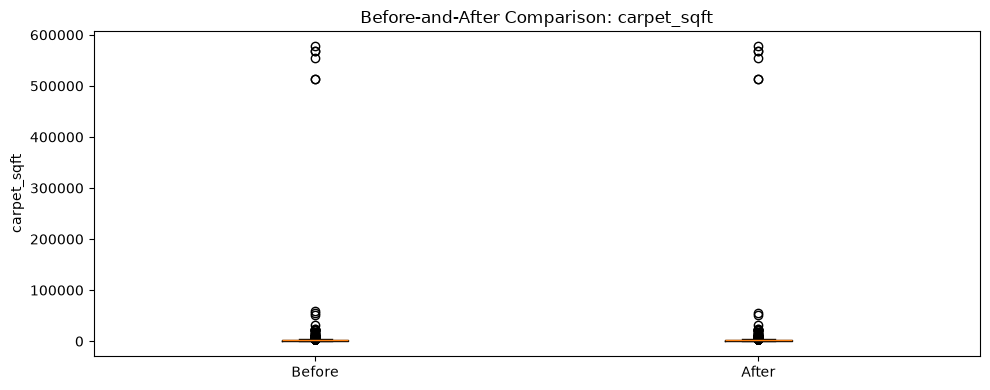

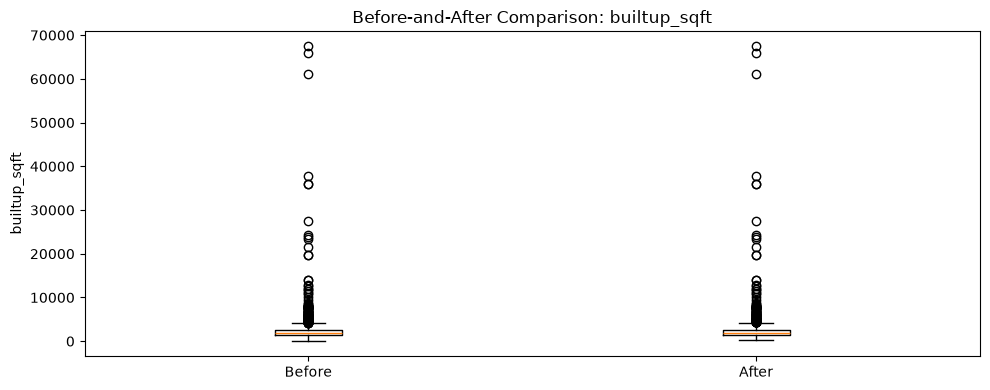

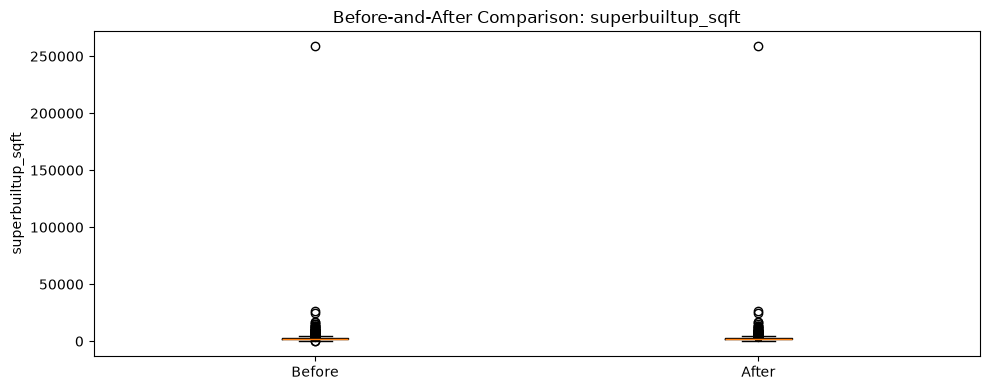

Skipping price_lakhs: column not present in both datasets.


In [90]:
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

raw_path = "../data/raw/housing_raw.csv"
processed_path = "../data/processed/clean.csv"

df_before = pd.read_csv(raw_path)
df_after = pd.read_csv(processed_path)

# Standardize names in the raw copy so the column names are easier to compare.
df_before.columns = (
    df_before.columns
    .str.strip()
    .str.lower()
    .str.replace(" ", "_", regex=False)
    .str.replace("-", "_", regex=False)
)

# Use columns present in both datasets.
candidate_columns = [
    "carpet_sqft",
    "builtup_sqft",
    "superbuiltup_sqft",
    "price_lakhs"
]

for col in candidate_columns:
    if col not in df_before.columns or col not in df_after.columns:
        print(f"Skipping {col}: column not present in both datasets.")
        continue

    before_values = pd.to_numeric(
        df_before[col], errors="coerce"
    ).dropna()

    after_values = pd.to_numeric(
        df_after[col], errors="coerce"
    ).dropna()

    if before_values.empty or after_values.empty:
        print(f"Skipping {col}: no valid numeric values.")
        continue

    plt.figure(figsize=(10, 4))

    plt.boxplot(
        [before_values, after_values],
        tick_labels=["Before", "After"]
    )

    plt.title(f"Before-and-After Comparison: {col}")
    plt.ylabel(col)
    plt.tight_layout()
    plt.show()

In [92]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

raw_path = "../data/raw/housing_raw.csv"

df = pd.read_csv(raw_path, low_memory=False)

# Standardize column names
df.columns = (
    df.columns.str.strip()
    .str.lower()
    .str.replace(" ", "_", regex=False)
    .str.replace("-", "_", regex=False)
)

# Clean whitespace in text columns
for col in df.select_dtypes(include=["object", "str"]).columns:
    df[col] = df[col].str.strip()

print("Dataset shape:", df.shape)
print("\nColumns:")
print(df.columns.tolist())

Dataset shape: (10704, 67)

Columns:
['prop_id', 'photo_url', 'medium_photo_url', 'preference', 'description', 'property_type', 'city', 'locality', 'transact_type', 'owntype', 'bedroom_num', 'bathroom_num', 'balcony_num', 'price_per_unit_area', 'furnish', 'facing', 'age', 'floor_num', 'total_floor', 'features', 'register_date', 'prop_name', 'min_price', 'max_price', 'price_sqft', 'listing', 'building_id', 'carpet_sqft', 'superbuiltup_sqft', 'brokerage', 'map_details', 'fsl_data', 'min_area_sqft', 'max_area_sqft', 'formatted', 'amenities', 'top_usps', 'pd_url', 'expiry_date', 'group_name', 'area', 'price', 'prop_heading', 'prop_details_url', 'class_heading', 'class_label', 'secondary_tags', 'property_images', 'thumbnail_images', 'total_landmark_count', 'formatted_landmark_details', 'contact_name', 'contact_company_name', 'dealer_photo_url', 'society_name', 'building_name', 'city_id', 'locality_wo_city', 'profile', 'xid', 'metadata', 'location', 'builtup_sqft', 'super_sqft', 'common_furn

In [93]:
print("Listings before filtering:")
print(df["preference"].value_counts(dropna=False))

print("\nRows before filtering:", len(df))

df = df[df["preference"] == "S"].copy()

print("\nRows after filtering:", len(df))
print("Sale listings retained:", len(df))
print("\nListings after filtering:")
print(df["preference"].value_counts(dropna=False))

print("\nPrice summary:")
print(df["price_lakhs"].describe() if "price_lakhs" in df.columns
      else df["price"].head())

Listings before filtering:
preference
S    10155
R      549
Name: count, dtype: int64

Rows before filtering: 10704

Rows after filtering: 10155
Sale listings retained: 10155

Listings after filtering:
preference
S    10155
Name: count, dtype: int64

Price summary:
0    2.63 Cr
1     3.6 Cr
3    3.85 Cr
5    1.95 Cr
7    1.62 Cr
Name: price, dtype: str


In [94]:
import re
import numpy as np
import pandas as pd

def convert_price_to_lakhs(value):
    if pd.isna(value):
        return np.nan

    text = str(value).lower().strip()
    text = text.replace(",", "").replace("₹", "").replace("rs.", "").replace("rs", "").strip()

    numbers = re.findall(r"\d+(?:\.\d+)?", text)

    if not numbers:
        return np.nan

    amount = float(numbers[0])

    if "crore" in text or "crores" in text or "cr" in text:
        return amount * 100
    elif "lakh" in text or "lac" in text:
        return amount
    else:
        return amount / 100000


df["price_lakhs"] = df["price"].apply(convert_price_to_lakhs)

print("Missing prices:", df["price_lakhs"].isna().sum())
print("\nPrice summary (lakhs):")
print(df["price_lakhs"].describe())

print("\nSample converted prices:")
print(df[["price", "price_lakhs"]].head(15))

Missing prices: 22

Price summary (lakhs):
count    10133.000000
mean       329.808513
std        566.508704
min          0.000010
25%        150.000000
50%        230.000000
75%        380.000000
max      29000.000000
Name: price_lakhs, dtype: float64

Sample converted prices:
      price  price_lakhs
0   2.63 Cr        263.0
1    3.6 Cr        360.0
3   3.85 Cr        385.0
5   1.95 Cr        195.0
7   1.62 Cr        162.0
8   2.17 Cr        217.0
9    2.2 Cr        220.0
10  4.16 Cr        416.0
11   7.5 Cr        750.0
12   1.6 Cr        160.0
14   3.5 Cr        350.0
15  2.58 Cr        258.0
16   4.5 Cr        450.0
17  1.55 Cr        155.0
18   1.9 Cr        190.0


In [91]:
# 1. First five rows of the modelling dataset
print("========== DF_MODEL HEAD ==========")
display(df_model.head())

# 2. Data types of all columns
print("\n========== DF_MODEL DTYPES ==========")
print(df_model.dtypes.to_string())

# 3. Final dataset dimensions
print("\n========== FINAL SHAPE ==========")
print(df_model.shape)

# 4. Target column check
print("\n========== TARGET CHECK ==========")

if "price_lakhs" in df_model.columns:
    print("Target column exists: price_lakhs")
    print("Target data type:", df_model["price_lakhs"].dtype)
    print("Missing target values:", df_model["price_lakhs"].isna().sum())
else:
    print("WARNING: price_lakhs is not present in df_model.")

# 5. Check missing values
print("\n========== MISSING VALUES ==========")
print(df_model.isna().sum().to_string())

========== DF_MODEL HEAD ==========


,prop_id,photo_url,medium_photo_url,preference,description,property_type,locality,transact_type,owntype,bedroom_num,...,metadata,location,builtup_sqft,super_sqft,furnishing_attributes,latitude,longitude,price_lakhs,locality_grouped,log_price_target
0,O71585872,https://mediacdn.99acres.com/media1/22409/13/4...,https://mediacdn.99acres.com/media1/22409/13/4...,S,4 bhk flat for resale in alpha corp gurgaon one,Residential Apartment,Sector 84 Gurgaon,1.0,1,4.0,...,"{'PROP_PHOTO_COUNT': '4', 'PROP_VIDEO_COUNT': ...","{'CITY': '8', 'CITY_NAME': 'Gurgaon', 'BUILDIN...",NaN,NaN,NaN,28.403547,76.967789,263.00,Sector 84 Gurgaon,5.575949
1,T71585466,https://mediacdn.99acres.com/media1/22425/6/44...,https://mediacdn.99acres.com/media1/22425/6/44...,S,"Explore dlf ultima, an upscale ready-To-Move h...",Residential Apartment,Sector 81 Gurgaon,1.0,1,4.0,...,"{'PROP_PHOTO_COUNT': '4', 'PROP_VIDEO_COUNT': ...","{'CITY': '8', 'CITY_NAME': 'Gurgaon', 'BUILDIN...",NaN,NaN,NaN,28.387365,76.947583,360.00,Sector 81 Gurgaon,5.888878
2,D71549524,https://mediacdn.99acres.com/media1/22386/13/4...,https://mediacdn.99acres.com/media1/22386/13/4...,R,A 3 bhk flat for rent in sector 66 gurgaon clo...,Residential Apartment,Sector 66 Gurgaon,NaN,0,3.0,...,"{'PROP_PHOTO_COUNT': '1', 'PROP_VIDEO_COUNT': ...","{'CITY': '8', 'CITY_NAME': 'Gurgaon', 'BUILDIN...",1920.00,NaN,NaN,28.397429,77.053882,0.85,Sector 66 Gurgaon,0.615186
3,I71493958,https://mediacdn.99acres.com/media1/22353/14/4...,https://mediacdn.99acres.com/media1/22353/14/4...,S,Looking for a 3 bhk property for purchase in g...,Residential Apartment,Sector 112 Gurgaon,1.0,1,3.0,...,"{'PROP_PHOTO_COUNT': '1', 'PROP_VIDEO_COUNT': ...","{'CITY': '8', 'CITY_NAME': 'Gurgaon', 'BUILDIN...",2225.56,NaN,NaN,28.520340,77.018861,385.00,Sector 112 Gurgaon,5.955837
4,H71479412,https://mediacdn.99acres.com/media1/22352/4/44...,https://mediacdn.99acres.com/media1/22352/4/44...,R,This 4 bhk flat in sector 104 gurgaon is avail...,Residential Apartment,Sector 104 Gurgaon,NaN,0,3.0,...,"{'PROP_PHOTO_COUNT': '14', 'PROP_VIDEO_COUNT':...","{'CITY': '8', 'CITY_NAME': 'Gurgaon', 'BUILDIN...",NaN,NaN,NaN,28.479532,76.993720,0.40,Sector 104 Gurgaon,0.336472



========== DF_MODEL DTYPES ==========
prop_id                           str
photo_url                         str
medium_photo_url                  str
preference                        str
description                       str
property_type                     str
locality                          str
transact_type                 float64
owntype                         int64
bedroom_num                   float64
bathroom_num                    int64
balcony_num                   float64
furnish                         int64
facing                          int64
age                             int64
floor_num                         str
total_floor                   float64
features                          str
register_date                     str
prop_name                         str
listing                           str
building_id                     int64
carpet_sqft                   float64
superbuiltup_sqft             float64
brokerage                     float64
map_details

In [95]:
df = df[
    df["price_lakhs"].notna() &
    (df["price_lakhs"] > 0)
].copy()

print("Rows after removing invalid prices:", len(df))
print("\nPrice summary:")
print(df["price_lakhs"].describe())

print("\nPrice range:")
print("Minimum:", df["price_lakhs"].min(), "lakhs")
print("Maximum:", df["price_lakhs"].max(), "lakhs")

Rows after removing invalid prices: 10133

Price summary:
count    10133.000000
mean       329.808513
std        566.508704
min          0.000010
25%        150.000000
50%        230.000000
75%        380.000000
max      29000.000000
Name: price_lakhs, dtype: float64

Price range:
Minimum: 1e-05 lakhs
Maximum: 29000.0 lakhs


In [96]:
print("Prices below 1 lakh:", (df["price_lakhs"] < 1).sum())
print("Prices above 5000 lakhs:", (df["price_lakhs"] > 5000).sum())

df = df[
    (df["price_lakhs"] >= 1) &
    (df["price_lakhs"] <= 5000)
].copy()

print("\nRows after price filtering:", len(df))
print("\nUpdated price summary:")
print(df["price_lakhs"].describe())

Prices below 1 lakh: 1050
Prices above 5000 lakhs: 8

Rows after price filtering: 9075

Updated price summary:
count    9075.000000
mean      356.754711
std       371.261653
min       100.000000
25%       170.000000
50%       250.000000
75%       405.000000
max      5000.000000
Name: price_lakhs, dtype: float64


In [97]:
area_cols = [
    "carpet_sqft",
    "superbuiltup_sqft",
    "super_sqft",
    "builtup_sqft",
    "min_area_sqft",
    "max_area_sqft",
    "area"
]

print("Available area columns:")
print(df[[col for col in area_cols if col in df.columns]].notna().sum())

print("\nSample area values:")
print(df[[col for col in area_cols if col in df.columns]].head(15))

Available area columns:
carpet_sqft          5355
superbuiltup_sqft    5742
super_sqft            794
builtup_sqft         2297
min_area_sqft        9075
max_area_sqft        9075
area                 9075
dtype: int64

Sample area values:
    carpet_sqft  superbuiltup_sqft  super_sqft  builtup_sqft  min_area_sqft  \
0        3000.0             3434.0         NaN           NaN     319.028902   
1        1700.0             2870.0         NaN           NaN     266.631610   
3           NaN             2802.0         NaN       2225.56     260.314206   
5           NaN             2290.0         NaN           NaN     212.747870   
7           NaN             1400.0         NaN           NaN     130.064200   
8           NaN                NaN      1629.0           NaN     151.338987   
9           NaN             2727.0         NaN           NaN     253.346481   
10          NaN                NaN      2340.0           NaN     217.393020   
11       3080.0             4850.0         NaN   

In [98]:
df["area_sqft"] = (
    df["superbuiltup_sqft"]
    .combine_first(df["super_sqft"])
    .combine_first(df["builtup_sqft"])
    .combine_first(df["carpet_sqft"])
)

# Fill remaining missing values using min/max area in square feet
df["min_area_sqft"] = pd.to_numeric(df["min_area_sqft"], errors="coerce")
df["max_area_sqft"] = pd.to_numeric(df["max_area_sqft"], errors="coerce")

df["area_sqft"] = df["area_sqft"].combine_first(
    (df["min_area_sqft"] + df["max_area_sqft"]) / 2
)

print("Missing area values:", df["area_sqft"].isna().sum())
print("\nArea summary:")
print(df["area_sqft"].describe())

print("\nSample results:")
print(df[["carpet_sqft", "superbuiltup_sqft", "builtup_sqft",
          "min_area_sqft", "max_area_sqft", "area_sqft"]].head(15))

Missing area values: 0

Area summary:
count      9075.000000
mean       2675.434744
std        9901.643670
min           0.000000
25%        1741.500000
50%        2191.000000
75%        2812.000000
max      784080.000000
Name: area_sqft, dtype: float64

Sample results:
    carpet_sqft  superbuiltup_sqft  builtup_sqft  min_area_sqft  \
0        3000.0             3434.0           NaN     319.028902   
1        1700.0             2870.0           NaN     266.631610   
3           NaN             2802.0       2225.56     260.314206   
5           NaN             2290.0           NaN     212.747870   
7           NaN             1400.0           NaN     130.064200   
8           NaN                NaN           NaN     151.338987   
9           NaN             2727.0           NaN     253.346481   
10          NaN                NaN           NaN     217.393020   
11       3080.0             4850.0           NaN     450.579550   
12          NaN             1400.0           NaN     130.06

In [99]:
print("Area below or equal to 0:", (df["area_sqft"] <= 0).sum())
print("Area below 100 sqft:", (df["area_sqft"] < 100).sum())
print("Area above 20000 sqft:", (df["area_sqft"] > 20000).sum())

df = df[
    (df["area_sqft"] >= 100) &
    (df["area_sqft"] <= 20000)
].copy()

print("\nRows after area filtering:", len(df))
print("\nArea summary:")
print(df["area_sqft"].describe())

Area below or equal to 0: 2
Area below 100 sqft: 3
Area above 20000 sqft: 15

Rows after area filtering: 9057

Area summary:
count     9057.000000
mean      2476.030618
std       1245.438819
min        111.158440
25%       1741.000000
50%       2190.000000
75%       2810.000000
max      16668.000000
Name: area_sqft, dtype: float64


In [100]:
print("Dataset shape:", df.shape)

print("\nMissing values:")
print(df.isna().sum().sort_values(ascending=False).head(25))

print("\nData types:")
print(df.dtypes)

Dataset shape: (9057, 69)

Missing values:
common_furnishing_attributes    9057
quality_score                   9057
furnishing_attributes           9057
super_sqft                      8271
builtup_sqft                    6763
carpet_sqft                     3711
superbuiltup_sqft               3320
top_usps                        2019
photo_url                       1555
medium_photo_url                1555
property_images                 1554
thumbnail_images                1554
society_name                    1435
building_name                   1435
prop_name                       1435
floor_num                        807
balcony_num                      164
bedroom_num                      154
amenities                         64
brokerage                         57
total_landmark_count              51
formatted_landmark_details        51
contact_name                      40
total_floor                        7
transact_type                      3
dtype: int64

Data types:
prop_i

In [101]:
drop_cols = [
    "prop_id", "photo_url", "medium_photo_url", "description",
    "features", "register_date", "expiry_date", "prop_name",
    "prop_heading", "listing", "building_id", "map_details",
    "fsl_data", "amenities", "top_usps", "pd_url",
    "prop_details_url", "group_name", "class_heading",
    "class_label", "secondary_tags", "property_images",
    "thumbnail_images", "contact_name", "contact_company_name",
    "dealer_photo_url", "profile", "xid", "metadata",
    "location", "furnishing_attributes", "common_furnishing_attributes",
    "quality_score", "formatted_landmark_details", "society_name",
    "building_name", "locality_wo_city", "city_id",
    "min_price", "max_price", "price_sqft", "price_per_unit_area",
    "formatted", "price", "area", "min_area_sqft", "max_area_sqft",
    "carpet_sqft", "superbuiltup_sqft", "builtup_sqft", "super_sqft",
    "preference", "transact_type"
]

df.drop(columns=drop_cols, errors="ignore", inplace=True)

print("Dataset shape:", df.shape)
print("\nRemaining columns:")
print(df.columns.tolist())

Dataset shape: (9057, 16)

Remaining columns:
['property_type', 'city', 'locality', 'owntype', 'bedroom_num', 'bathroom_num', 'balcony_num', 'furnish', 'facing', 'age', 'floor_num', 'total_floor', 'brokerage', 'total_landmark_count', 'price_lakhs', 'area_sqft']


In [102]:
categorical_cols = [
    "property_type",
    "city",
    "locality",
    "owntype",
    "furnish",
    "facing",
    "age",
    "floor_num"
]

for col in categorical_cols:
    if col in df.columns:
        print(f"\n--- {col} ---")
        print(df[col].value_counts(dropna=False).head(20))


--- property_type ---
property_type
Residential Apartment        5765
Independent/Builder Floor    2485
Independent House/Villa       661
Residential Land              146
Name: count, dtype: int64

--- city ---
city
Gurgaon    9057
Name: count, dtype: int64

--- locality ---
locality
Sector 65 Gurgaon      331
Sector 48 Gurgaon      256
Sector 102 Gurgaon     254
DLF Phase 2            254
Sector 54 Gurgaon      243
DLF Phase 1            222
Sector 57 Gurgaon      185
Sector-33 Sohna        183
Sector 79 Gurgaon      176
Nirvana Country        167
Sushant Lok Phase 1    165
Sector 113 Gurgaon     164
Sector 67 Gurgaon      164
Sector 66 Gurgaon      163
Sector 62 Gurgaon      161
Palam Vihar            157
Sector 59 Gurgaon      154
Sector 106 Gurgaon     151
Sector 104 Gurgaon     146
Sector 81 Gurgaon      145
Name: count, dtype: int64

--- owntype ---
owntype
1    8963
2      49
3      34
4      11
Name: count, dtype: int64

--- furnish ---
furnish
4    6823
2    1154
1     644
0

In [103]:
numeric_cols = [
    "bedroom_num",
    "bathroom_num",
    "balcony_num",
    "total_floor",
    "total_landmark_count",
    "brokerage",
    "age",
    "floor_num",
    "area_sqft",
    "price_lakhs"
]

for col in numeric_cols:
    if col in df.columns:
        df[col] = pd.to_numeric(df[col], errors="coerce")

print("Missing values:")
print(df.isna().sum())

print("\nData types:")
print(df.dtypes)

Missing values:
property_type              0
city                       0
locality                   0
owntype                    0
bedroom_num              154
bathroom_num               0
balcony_num              164
furnish                    0
facing                     0
age                        0
floor_num               1166
total_floor                7
brokerage                 57
total_landmark_count      51
price_lakhs                0
area_sqft                  0
dtype: int64

Data types:
property_type               str
city                        str
locality                    str
owntype                   int64
bedroom_num             float64
bathroom_num              int64
balcony_num             float64
furnish                   int64
facing                    int64
age                       int64
floor_num               float64
total_floor             float64
brokerage               float64
total_landmark_count    float64
price_lakhs             float64
area_sqft     

In [104]:
# Fill missing numeric values with the median
for col in ["bedroom_num", "balcony_num", "total_floor",
            "brokerage", "total_landmark_count"]:
    df[col] = df[col].fillna(df[col].median())

# Missing floor number will remain unknown; use -1 as a separate marker
df["floor_num"] = df["floor_num"].fillna(-1)

# Remove rows with missing bedroom count
df = df.dropna(subset=["bedroom_num"]).copy()

print("Dataset shape:", df.shape)
print("\nMissing values remaining:")
print(df.isna().sum())

Dataset shape: (9057, 16)

Missing values remaining:
property_type           0
city                    0
locality                0
owntype                 0
bedroom_num             0
bathroom_num            0
balcony_num             0
furnish                 0
facing                  0
age                     0
floor_num               0
total_floor             0
brokerage               0
total_landmark_count    0
price_lakhs             0
area_sqft               0
dtype: int64


In [105]:
locality_counts = df["locality"].value_counts()

df["locality_grouped"] = df["locality"].where(
    df["locality"].map(locality_counts) >= 20,
    "Other"
)

print("Unique localities before:", df["locality"].nunique())
print("Unique localities after:", df["locality_grouped"].nunique())

print("\nMost common localities:")
print(df["locality_grouped"].value_counts().head(20))

Unique localities before: 192
Unique localities after: 95

Most common localities:
locality_grouped
Other                  438
Sector 65 Gurgaon      331
Sector 48 Gurgaon      256
Sector 102 Gurgaon     254
DLF Phase 2            254
Sector 54 Gurgaon      243
DLF Phase 1            222
Sector 57 Gurgaon      185
Sector-33 Sohna        183
Sector 79 Gurgaon      176
Nirvana Country        167
Sushant Lok Phase 1    165
Sector 113 Gurgaon     164
Sector 67 Gurgaon      164
Sector 66 Gurgaon      163
Sector 62 Gurgaon      161
Palam Vihar            157
Sector 59 Gurgaon      154
Sector 106 Gurgaon     151
Sector 104 Gurgaon     146
Name: count, dtype: int64


In [106]:
from pathlib import Path

output_path = Path("../data/processed/clean.csv")
output_path.parent.mkdir(parents=True, exist_ok=True)

df.to_csv(output_path, index=False)

print("Preprocessing completed!")
print("Dataset shape:", df.shape)
print("Saved to:", output_path.resolve())

print("\nFinal columns:")
print(df.columns.tolist())

print("\nMissing values:", df.isna().sum().sum())

Preprocessing completed!
Dataset shape: (9057, 17)
Saved to: D:\real-estate-price-prediction\data\processed\clean.csv

Final columns:
['property_type', 'city', 'locality', 'owntype', 'bedroom_num', 'bathroom_num', 'balcony_num', 'furnish', 'facing', 'age', 'floor_num', 'total_floor', 'brokerage', 'total_landmark_count', 'price_lakhs', 'area_sqft', 'locality_grouped']

Missing values: 0


1. df_model.shape
(9057, 17)

2. df_model.dtypes
property_type               str
city                        str
locality                    str
owntype                   int64
bedroom_num             float64
bathroom_num              int64
balcony_num             float64
furnish                   int64
facing                    int64
age                       int64
floor_num               float64
total_floor             float64
brokerage               float64
total_landmark_count    float64
price_lakhs             float64
area_sqft               float64
locality_grouped            str


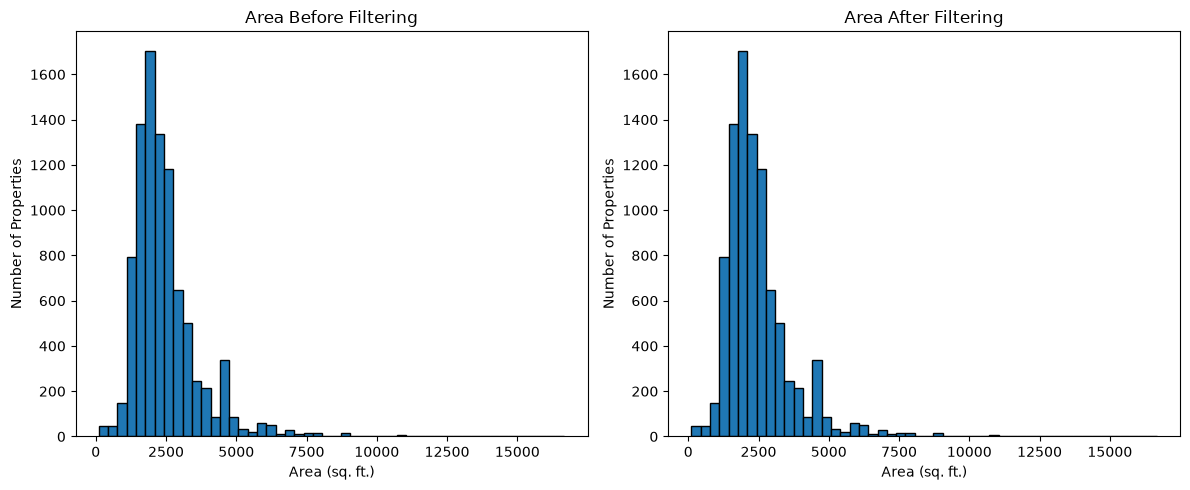


4. Numeric summary
       price_lakhs     area_sqft  bedroom_num
count  9057.000000   9057.000000  9057.000000
mean    356.015458   2476.030618     3.460197
std     369.025457   1245.438819     1.283470
min     100.000000    111.158440     1.000000
25%     170.000000   1741.000000     3.000000
50%     250.000000   2190.000000     3.000000
75%     405.000000   2810.000000     4.000000
max    5000.000000  16668.000000    22.000000


In [107]:
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

# Load the cleaned dataset
df_model = pd.read_csv("../data/processed/clean.csv")

# 1. Dataset shape
print("1. df_model.shape")
print(df_model.shape)

# 2. Full data types
print("\n2. df_model.dtypes")
print(df_model.dtypes.to_string())

# 3. Area distribution before and after filtering
df_before = pd.read_csv("../data/processed/clean.csv")

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.hist(df_before["area_sqft"].dropna(), bins=50, edgecolor="black")
plt.title("Area Before Filtering")
plt.xlabel("Area (sq. ft.)")
plt.ylabel("Number of Properties")

area_filtered = df_model[
    df_model["area_sqft"].between(100, 20000)
]

plt.subplot(1, 2, 2)
plt.hist(area_filtered["area_sqft"].dropna(), bins=50, edgecolor="black")
plt.title("Area After Filtering")
plt.xlabel("Area (sq. ft.)")
plt.ylabel("Number of Properties")

plt.tight_layout()
plt.show()

# 4. Numeric summary
print("\n4. Numeric summary")
print(
    df_model[["price_lakhs", "area_sqft", "bedroom_num"]]
    .describe()
)

Rows removed: 271
Rows remaining: 8786

Coordinates are not present in clean.csv.
Check the earlier dataframe or geocoded dataset before proceeding.

Brokerage-price correlation:
             brokerage  price_lakhs
brokerage     1.000000     0.047351
price_lakhs   0.047351     1.000000
Zero brokerage share: 0.17778283633052583

Original rent/sale distribution:
preference
S    10155
R      549
Name: count, dtype: int64

Area values between 4400 and 4700 sqft:
area_sqft
4500.0    86
4500.0    62
4518.0    53
4518.0    29
4680.0    11
Name: count, dtype: int64

Duplicate rows: 27

owntype value counts:
{1: 8693, 2: 49, 3: 34, 4: 10}

furnish value counts:
{4: 6655, 2: 1140, 1: 579, 0: 412}

facing value counts:
{5: 2966, 3: 2031, 1: 1248, 0: 980, 4: 549, 7: 308, 6: 304, 2: 209, 8: 191}

age value counts:
{1: 2857, 6: 2376, 5: 1526, 2: 1312, 3: 583, 0: 132}

Missing values before handling:
property_type           0
owntype                 0
bedroom_num             0
bathroom_num           

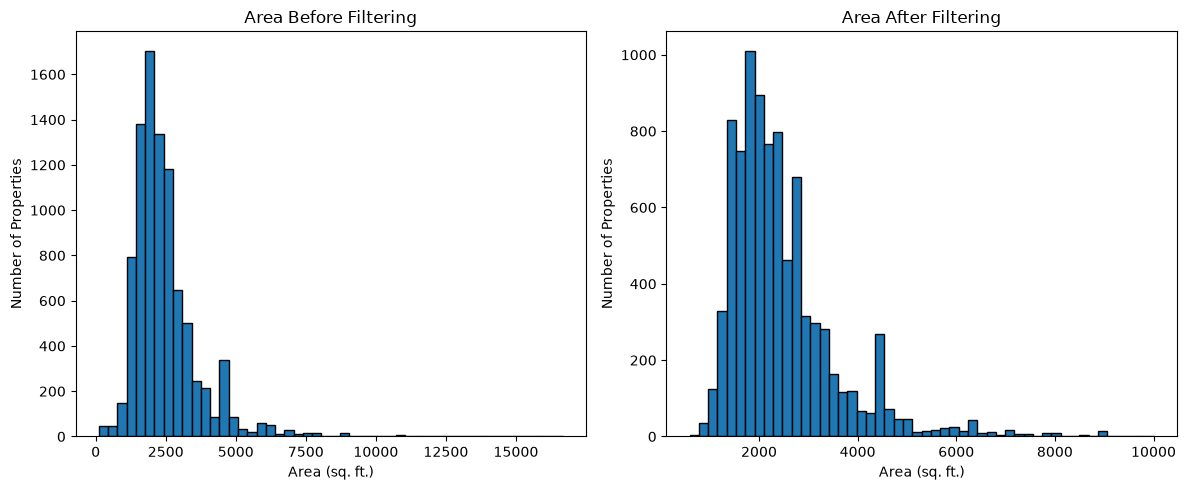


Final df_model.shape:
(8786, 15)

Missing values:
property_type           0
owntype                 0
bedroom_num             0
bathroom_num            0
balcony_num             0
furnish                 0
facing                  0
age                     0
floor_num               0
total_floor             0
brokerage               0
total_landmark_count    0
price_lakhs             0
area_sqft               0
locality_grouped        0
dtype: int64

Descriptive statistics:
                       count          mean            std    min     25%  \
bedroom_num           8786.0      3.336331       0.760818    1.0     3.0   
bathroom_num          8786.0      3.540747       1.098864    0.0     3.0   
balcony_num           8786.0      3.001707       0.863539    0.0     2.0   
floor_num             8786.0      6.757227       6.788949   -1.0     2.0   
total_floor           8786.0     15.487480      11.710379    0.0     4.0   
brokerage             8786.0  52845.555998  862560.664095    0.0 

In [108]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Load datasets
df_raw = pd.read_csv("../data/raw/housing_raw.csv", low_memory=False)
df = pd.read_csv("../data/processed/clean.csv")

# Standardize raw column names
df_raw.columns = (
    df_raw.columns.str.strip()
    .str.lower()
    .str.replace(" ", "_", regex=False)
    .str.replace("-", "_", regex=False)
)

# Preserve original cleaned data for comparison
df_before = df.copy()
n0 = len(df)

# 1. Apply outlier filters
df = df[
    df["area_sqft"].between(400, 10000)
    & df["bedroom_num"].between(1, 8)
].copy()

df = df[
    (df["area_sqft"] / df["bedroom_num"] >= 250)
    & (df["bathroom_num"] <= df["bedroom_num"] + 2)
].copy()

# Price-per-square-foot sanity filter
pps = df["price_lakhs"] * 100000 / df["area_sqft"]
df = df[pps.between(3000, 60000)].copy()

print("Rows removed:", n0 - len(df))
print("Rows remaining:", len(df))

# 2. Restore coordinates if available in the cleaned dataframe
if {"latitude", "longitude"}.issubset(df.columns):
    pass
elif {"latitude", "longitude"}.issubset(df_before.columns):
    df[["latitude", "longitude"]] = df_before.loc[
        df.index, ["latitude", "longitude"]
    ]
else:
    print("\nCoordinates are not present in clean.csv.")
    print("Check the earlier dataframe or geocoded dataset before proceeding.")

# Validate Gurgaon coordinates if available
if {"latitude", "longitude"}.issubset(df.columns):
    df["latitude"] = pd.to_numeric(df["latitude"], errors="coerce")
    df["longitude"] = pd.to_numeric(df["longitude"], errors="coerce")

    valid_coords = (
        df["latitude"].between(28.30, 28.55)
        & df["longitude"].between(76.80, 77.20)
    )

    print("\nMissing coordinates:")
    print(df[["latitude", "longitude"]].isna().sum())
    print("Coordinates within Gurgaon bounding box:", valid_coords.sum())
    print("Coordinates outside bounding box:", (~valid_coords).sum())

# 3. Check brokerage leakage
if "brokerage" in df.columns:
    print("\nBrokerage-price correlation:")
    print(df[["brokerage", "price_lakhs"]].corr())
    print("Zero brokerage share:", (df["brokerage"] == 0).mean())

    corr = df["brokerage"].corr(df["price_lakhs"])
    if pd.notna(corr) and abs(corr) > 0.5:
        df.drop(columns=["brokerage"], inplace=True)
        print("Dropped brokerage due to strong price correlation.")

# 4. Verify source rent/sale categories
if "preference" in df_raw.columns:
    print("\nOriginal rent/sale distribution:")
    print(df_raw["preference"].value_counts(dropna=False))

# 5. Remove unhelpful columns
df.drop(
    columns=["city", "locality", "price_per_sqft", "price_per_unit_area"],
    errors="ignore",
    inplace=True
)

# Check possible area duplicates/default values
print("\nArea values between 4400 and 4700 sqft:")
print(
    df.loc[df["area_sqft"].between(4400, 4700), "area_sqft"]
    .value_counts()
    .head()
)

print("\nDuplicate rows:", df.duplicated().sum())

# 6. Inspect category codes
for col in ["owntype", "furnish", "facing", "age"]:
    if col in df.columns:
        print(f"\n{col} value counts:")
        print(df[col].value_counts(dropna=False).to_dict())

# 7. Check and handle missing values
print("\nMissing values before handling:")
print(df.isna().sum())

categorical_cols = [
    "property_type", "locality_grouped",
    "owntype", "furnish", "facing", "age"
]

for col in categorical_cols:
    if col in df.columns:
        df[col] = df[col].fillna("Unknown").astype(str)

numeric_cols = df.select_dtypes(include=["number"]).columns.tolist()

for col in numeric_cols:
    if col not in ["latitude", "longitude"]:
        df[col] = df[col].fillna(df[col].median())

# Keep missing coordinates missing for later geocoding/validation

# 8. Plot area before and after filtering
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

axes[0].hist(df_before["area_sqft"].dropna(), bins=50, edgecolor="black")
axes[0].set_title("Area Before Filtering")
axes[0].set_xlabel("Area (sq. ft.)")
axes[0].set_ylabel("Number of Properties")

axes[1].hist(df["area_sqft"].dropna(), bins=50, edgecolor="black")
axes[1].set_title("Area After Filtering")
axes[1].set_xlabel("Area (sq. ft.)")
axes[1].set_ylabel("Number of Properties")

plt.tight_layout()
plt.show()

# 9. Final validation
print("\nFinal df_model.shape:")
df_model = df.copy()
print(df_model.shape)

print("\nMissing values:")
print(df_model.isna().sum())

print("\nDescriptive statistics:")
print(df_model.describe().T)

print("\nArea range:")
print(df_model["area_sqft"].min(), "to", df_model["area_sqft"].max())

print("\nBedroom range:")
print(df_model["bedroom_num"].min(), "to", df_model["bedroom_num"].max())

# Save updated dataset
output_path = "../data/processed/clean.csv"
df_model.to_csv(output_path, index=False)
print("\nSaved updated dataset to:", output_path)

In [109]:
import pandas as pd
import numpy as np
from pathlib import Path

# Load raw dataset
df_raw = pd.read_csv("../data/raw/housing_raw.csv", low_memory=False)

df_raw.columns = (
    df_raw.columns.str.strip()
    .str.lower()
    .str.replace(" ", "_", regex=False)
    .str.replace("-", "_", regex=False)
)

# Inspect coordinate-related columns
print("Coordinate-related columns:")
print(df_raw.columns[
    df_raw.columns.str.contains("lat|lon|map|geo|fsl", case=False)
].tolist())

if "map_details" in df_raw.columns:
    print("\nSample map_details:")
    print(df_raw["map_details"].dropna().head(3).to_string(index=False))

# Check original sale/rent distribution
if "preference" in df_raw.columns:
    print("\nPreference counts in raw dataset:")
    print(df_raw["preference"].value_counts(dropna=False))

# Load current filtered dataset
df_model = pd.read_csv("../data/processed/clean.csv")

# Brokerage inspection
if "brokerage" in df_model.columns:
    print("\nBrokerage description:")
    print(df_model["brokerage"].describe())

# Minimum and maximum price counts
print("\nMinimum price count:")
print((df_model["price_lakhs"] == df_model["price_lakhs"].min()).sum())

print("\nMaximum price count:")
print((df_model["price_lakhs"] == df_model["price_lakhs"].max()).sum())

# Area values around 4500 sqft
print("\nArea values between 4400 and 4700 sqft:")
print(
    df_model.loc[
        df_model["area_sqft"].between(4400, 4700), "area_sqft"
    ].value_counts().head(15)
)

# Exact duplicate count
print("\nExact duplicate rows:")
print(df_model.duplicated().sum())

# Potential near-duplicate count
duplicate_columns = [
    "locality_grouped", "area_sqft", "bedroom_num", "price_lakhs"
]
if all(col in df_model.columns for col in duplicate_columns):
    print("\nPotential near-duplicate rows:")
    print(df_model.duplicated(subset=duplicate_columns).sum())

# Check whether the raw file already has coordinate columns
coordinate_cols = [
    col for col in df_raw.columns
    if col in ["latitude", "longitude", "lat", "lon", "lng"]
]

print("\nDirect coordinate columns in raw dataset:")
print(coordinate_cols)

# Preserve original data and join key for rebuilding
if "prop_id" in df_raw.columns:
    print("\nRaw prop_id examples:")
    print(df_raw["prop_id"].head().to_list())

print("\nCurrent df_model columns:")
print(df_model.columns.tolist())

Coordinate-related columns:
['map_details', 'fsl_data']

Sample map_details:
{'LATITUDE': '28.4065341', 'LONGITUDE': '76.962...
{'LATITUDE': '28.3889069', 'LONGITUDE': '76.951...
{'LATITUDE': '28.401406', 'LONGITUDE': '77.0505...

Preference counts in raw dataset:
preference
S    10155
R      549
Name: count, dtype: int64

Brokerage description:
count    8.786000e+03
mean     5.284556e+04
std      8.625607e+05
min      0.000000e+00
25%      1.000000e+00
50%      1.000000e+00
75%      1.000000e+00
max      7.310000e+07
Name: brokerage, dtype: float64

Minimum price count:
51

Maximum price count:
1

Area values between 4400 and 4700 sqft:
area_sqft
4500.0    86
4500.0    62
4518.0    53
4518.0    29
4680.0    11
4600.0    11
4548.0    10
4495.0     7
4550.0     6
4615.0     5
4400.0     5
4690.0     4
4503.0     3
4480.0     3
4700.0     3
Name: count, dtype: int64

Exact duplicate rows:
27

Potential near-duplicate rows:
1136

Direct coordinate columns in raw dataset:
[]

Raw prop_id e

Price summary before outlier filtering:
count     9651.000000
mean       339.086886
std        554.432982
min          0.000010
25%        159.000000
50%        235.000000
75%        390.000000
max      29000.000000
Name: price_lakhs, dtype: float64

Row-count log:
                     Step  Rows
              Raw dataset 10704
       Sale listings only 10155
      Unique property IDs 10155
Valid Gurgaon coordinates  9672
  After outlier filtering  8400
  After duplicate removal  7457

Final shape:
(7457, 18)

Final columns:
['prop_id', 'latitude', 'longitude', 'property_type', 'owntype', 'bedroom_num', 'bathroom_num', 'balcony_num', 'furnish', 'facing', 'age', 'floor_num', 'total_floor', 'total_landmark_count', 'area_sqft', 'area_is_carpet', 'locality_grouped', 'price_lakhs']

Missing values:
prop_id                   0
latitude                  0
longitude                 0
property_type             0
owntype                   0
bedroom_num               0
bathroom_num              0

AttributeError: 'numpy.float64' object has no attribute 'dropna'

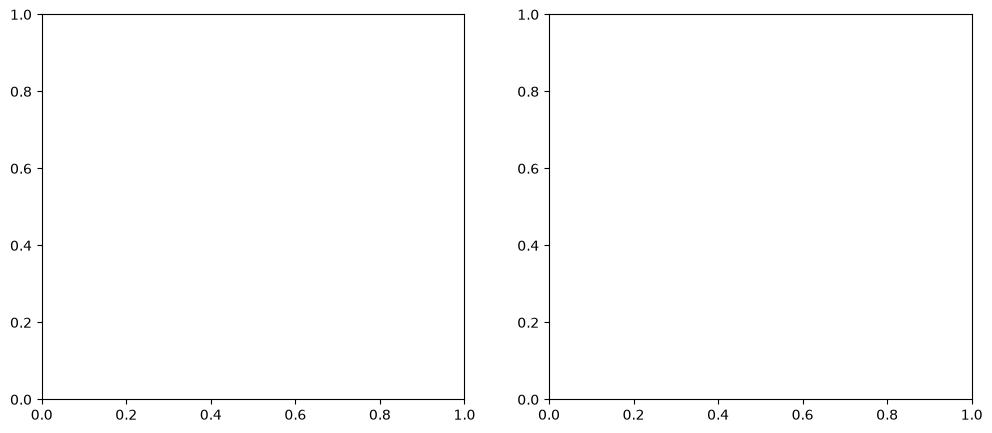

In [110]:
import ast
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

RAW = Path("../data/raw/housing_raw.csv")
OUT = Path("../data/processed/clean_v2.csv")

df = pd.read_csv(RAW, low_memory=False)

df.columns = (
    df.columns.str.strip()
    .str.lower()
    .str.replace(" ", "_", regex=False)
    .str.replace("-", "_", regex=False)
)

log = [("Raw dataset", len(df))]

# 1. Keep sale listings only
df = df[df["preference"].astype(str).str.strip().str.upper() == "S"].copy()
log.append(("Sale listings only", len(df)))

# 2. Remove duplicate property IDs
if "prop_id" in df.columns:
    df = df.drop_duplicates(subset=["prop_id"]).copy()
log.append(("Unique property IDs", len(df)))

# 3. Parse latitude and longitude
def parse_coords(value):
    try:
        data = value if isinstance(value, dict) else ast.literal_eval(str(value))
        lat = float(data.get("LATITUDE", data.get("latitude", np.nan)))
        lon = float(data.get("LONGITUDE", data.get("longitude", np.nan)))
        return lat, lon
    except (ValueError, SyntaxError, TypeError, AttributeError):
        return np.nan, np.nan

df[["latitude", "longitude"]] = pd.DataFrame(
    df["map_details"].apply(parse_coords).tolist(),
    index=df.index
)

df = df[
    df["latitude"].between(28.30, 28.55)
    & df["longitude"].between(76.80, 77.20)
].copy()

log.append(("Valid Gurgaon coordinates", len(df)))

# 4. Convert prices to lakhs
# CHECK: Verify that raw prices are numeric rupee amounts.
price_numeric = pd.to_numeric(
    df["price"].astype(str).str.replace(",", "", regex=False)
    .str.replace("₹", "", regex=False).str.strip(),
    errors="coerce"
)

if price_numeric.notna().mean() > 0.95:
    df["price_lakhs"] = price_numeric / 100000
else:
    import re

    def convert_price_to_lakhs(value):
        if pd.isna(value):
            return np.nan

        text = str(value).lower().replace(",", "").replace("₹", "").strip()
        match = re.search(r"\d+(?:\.\d+)?", text)

        if not match:
            return np.nan

        amount = float(match.group())
        if "crore" in text or "crores" in text or re.search(r"\bcr\b", text):
            return amount * 100
        if "lakh" in text or "lac" in text:
            return amount
        return amount / 100000

    df["price_lakhs"] = df["price"].apply(convert_price_to_lakhs)

df = df[
    df["price_lakhs"].notna()
    & (df["price_lakhs"] > 0)
].copy()

print("Price summary before outlier filtering:")
print(df["price_lakhs"].describe())

# 5. Create unified area column
area_columns = [
    "superbuiltup_sqft",
    "super_sqft",
    "builtup_sqft",
    "carpet_sqft"
]

for col in area_columns:
    if col in df.columns:
        df[col] = pd.to_numeric(df[col], errors="coerce")

df["area_is_carpet"] = (
    df[["superbuiltup_sqft", "super_sqft", "builtup_sqft"]]
    .isna()
    .all(axis=1)
    .astype(int)
)

df["area_sqft"] = (
    df["superbuiltup_sqft"]
    .combine_first(df["super_sqft"])
    .combine_first(df["builtup_sqft"])
    .combine_first(df["carpet_sqft"])
)

# 6. Convert relevant numeric columns
numeric_columns = [
    "bedroom_num", "bathroom_num", "balcony_num",
    "total_floor", "total_landmark_count", "age"
]

for col in numeric_columns:
    if col in df.columns:
        df[col] = pd.to_numeric(df[col], errors="coerce")

df["floor_num"] = pd.to_numeric(
    df["floor_num"].replace({
        "Ground": "0",
        "Basement": "-1",
        "Lower Ground": "-1"
    }),
    errors="coerce"
)

df = df.dropna(
    subset=["price_lakhs", "area_sqft", "bedroom_num", "bathroom_num"]
).copy()

# 7. Filter unrealistic values
df = df[
    df["area_sqft"].between(400, 10000)
    & df["bedroom_num"].between(1, 8)
].copy()

df = df[
    (df["area_sqft"] / df["bedroom_num"] >= 250)
    & (df["bathroom_num"] <= df["bedroom_num"] + 2)
].copy()

price_per_sqft = df["price_lakhs"] * 100000 / df["area_sqft"]
df = df[price_per_sqft.between(3000, 60000)].copy()

log.append(("After outlier filtering", len(df)))

# 8. Remove near-duplicate listings
df = df.drop_duplicates(
    subset=[
        "locality", "area_sqft", "bedroom_num",
        "bathroom_num", "price_lakhs"
    ]
).copy()

log.append(("After duplicate removal", len(df)))

# 9. Group rare localities
locality_counts = df["locality"].value_counts()
rare_localities = locality_counts[locality_counts < 10].index

df["locality_grouped"] = df["locality"].where(
    ~df["locality"].isin(rare_localities),
    "Other"
)

# 10. Keep useful columns
keep_columns = [
    "prop_id", "latitude", "longitude",
    "property_type", "owntype",
    "bedroom_num", "bathroom_num", "balcony_num",
    "furnish", "facing", "age", "floor_num", "total_floor",
    "total_landmark_count", "area_sqft", "area_is_carpet",
    "locality_grouped", "price_lakhs"
]

df = df[[col for col in keep_columns if col in df.columns]].copy()

# 11. Save without imputing missing values
df.reset_index(drop=True, inplace=True)
OUT.parent.mkdir(parents=True, exist_ok=True)
df.to_csv(OUT, index=False)

# 12. Final outputs
print("\nRow-count log:")
print(pd.DataFrame(log, columns=["Step", "Rows"]).to_string(index=False))

print("\nFinal shape:")
print(df.shape)

print("\nFinal columns:")
print(df.columns.tolist())

print("\nMissing values:")
print(df.isna().sum().to_string())

print("\nDescriptive statistics:")
print(df.describe().T.to_string())

print("\nPrice summary:")
print(df["price_lakhs"].describe())

print("\nCoordinate validation:")
print("Latitude range:", df["latitude"].min(), "to", df["latitude"].max())
print("Longitude range:", df["longitude"].min(), "to", df["longitude"].max())

# 13. Before/after area plots
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

axes[0].hist(
    pd.to_numeric(df_raw_area := pd.read_csv(RAW, low_memory=False)
                  .get("superbuiltup_sqft"), errors="coerce").dropna(),
    bins=50,
    edgecolor="black"
)
axes[0].set_title("Raw Super Built-up Area")
axes[0].set_xlabel("Area (sq. ft.)")
axes[0].set_ylabel("Listings")

axes[1].hist(df["area_sqft"].dropna(), bins=50, edgecolor="black")
axes[1].set_title("Filtered Property Area")
axes[1].set_xlabel("Area (sq. ft.)")
axes[1].set_ylabel("Listings")

plt.tight_layout()
plt.show()

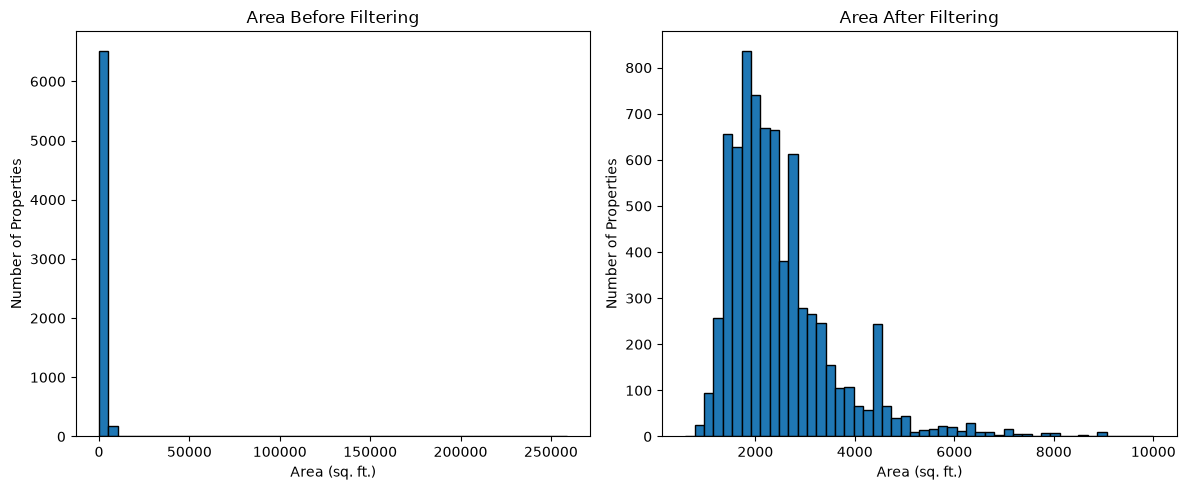

Raw area values: 6712
Filtered area values: 7457

Final dataset shape: (7457, 18)

Descriptive statistics:
                       count         mean          std        min          25%          50%          75%          max
latitude              7457.0    28.437972     0.041522   28.35093    28.406140    28.425181    28.472552     28.53481
longitude             7457.0    77.040553     0.052859   76.81076    76.997421    77.054558    77.084474     77.19150
owntype               7457.0     1.017299     0.178201    1.00000     1.000000     1.000000     1.000000      4.00000
bedroom_num           7457.0     3.378839     0.768965    1.00000     3.000000     3.000000     4.000000      8.00000
bathroom_num          7457.0     3.635778     1.020496    0.00000     3.000000     4.000000     4.000000      9.00000
balcony_num           7454.0     2.982426     0.875957    0.00000     2.000000     3.000000     4.000000      4.00000
furnish               7457.0     3.412230     1.138763    0.00000  

In [111]:
# Fix the before/after area plot

import pandas as pd
import matplotlib.pyplot as plt

df_raw = pd.read_csv("../data/raw/housing_raw.csv", low_memory=False)

df_raw.columns = (
    df_raw.columns.str.strip()
    .str.lower()
    .str.replace(" ", "_", regex=False)
    .str.replace("-", "_", regex=False)
)

area_col = "superbuiltup_sqft"

if area_col in df_raw.columns:
    area_before = pd.to_numeric(df_raw[area_col], errors="coerce").dropna()
else:
    area_before = pd.Series(dtype=float)

df_model = pd.read_csv("../data/processed/clean_v2.csv")
area_after = pd.to_numeric(df_model["area_sqft"], errors="coerce").dropna()

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

axes[0].hist(area_before, bins=50, edgecolor="black")
axes[0].set_title("Area Before Filtering")
axes[0].set_xlabel("Area (sq. ft.)")
axes[0].set_ylabel("Number of Properties")

axes[1].hist(area_after, bins=50, edgecolor="black")
axes[1].set_title("Area After Filtering")
axes[1].set_xlabel("Area (sq. ft.)")
axes[1].set_ylabel("Number of Properties")

plt.tight_layout()
plt.show()

print("Raw area values:", len(area_before))
print("Filtered area values:", len(area_after))
print("\nFinal dataset shape:", df_model.shape)
print("\nDescriptive statistics:")
print(df_model.describe().T.to_string())

In [112]:
import pandas as pd
import numpy as np

df_model = pd.read_csv("../data/processed/clean_v2.csv")

# 1. Check price conversion and minimum-price cutoff
print("Price summary:")
print(df_model["price_lakhs"].describe())

print("\nPrices below ₹100 lakhs in current dataset:", 
      (df_model["price_lakhs"] < 100).sum())

# 2. Check missing values
print("\nMissing values:")
print(df_model.isna().sum())

# 3. Check suspicious bedroom/bathroom values
print("\nBedroom counts:")
print(df_model["bedroom_num"].value_counts().sort_index())

print("\nBathroom counts:")
print(df_model["bathroom_num"].value_counts().sort_index())

# 4. Check category codes
for col in ["owntype", "furnish", "facing", "age"]:
    print(f"\n{col} counts:")
    print(df_model[col].value_counts(dropna=False).sort_index())

# 5. Check coordinate validity
print("\nMissing coordinates:")
print(df_model[["latitude", "longitude"]].isna().sum())

print("\nCoordinate ranges:")
print(df_model[["latitude", "longitude"]].agg(["min", "max"]))

# 6. Check area and price-per-square-foot distribution
df_model["price_per_sqft"] = (
    df_model["price_lakhs"] * 100000 / df_model["area_sqft"]
)

print("\nPrice per square foot summary:")
print(df_model["price_per_sqft"].describe())

# 7. Check duplicate listings
print("\nExact duplicate rows:", df_model.duplicated().sum())

print(
    "Potential duplicate listings:",
    df_model.duplicated(
        subset=[
            "locality_grouped",
            "area_sqft",
            "bedroom_num",
            "price_lakhs"
        ]
    ).sum()
)

# 8. Save a report-friendly summary
print("\nFinal dataset shape:", df_model.shape)
print("\nNumeric summary:")
print(df_model.describe().T.to_string())

Price summary:
count    7457.000000
mean      347.218318
std       307.582371
min       100.000000
25%       175.000000
50%       250.000000
75%       405.000000
max      4500.000000
Name: price_lakhs, dtype: float64

Prices below ₹100 lakhs in current dataset: 0

Missing values:
prop_id                   0
latitude                  0
longitude                 0
property_type             0
owntype                   0
bedroom_num               0
bathroom_num              0
balcony_num               3
furnish                   0
facing                    0
age                       0
floor_num               754
total_floor               2
total_landmark_count      2
area_sqft                 0
area_is_carpet            0
locality_grouped          0
price_lakhs               0
dtype: int64

Bedroom counts:
bedroom_num
1.0       7
2.0     663
3.0    3769
4.0    2644
5.0     303
6.0      42
7.0      19
8.0      10
Name: count, dtype: int64

Bathroom counts:
bathroom_num
0       3
1      10
